&nbsp;

# [fanta.bio](https://fanta.bio/) Data Visualization process

- Tags Per Million (TPM) データ の可視化などを行う

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import plotly.express as px
import matplotlib.pyplot as plt
from IPython.display import display


os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
Execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {Execute_date}")

Execute Date: 261015


&nbsp;

&nbsp;

## `fanta.bio` resource (sample annotation data)

- 使用されたCAGEデータのサンプル一覧を読み込む

In [3]:
fantabio_sample_metadata = pl.read_csv(
    "../../Data/Database/fantabio/fanta.bio-CREv1.2.1.metadata.human.sdrf.txt.gz",
    separator="\t"
)

display(fantabio_sample_metadata)

Source Name,Comment [biosample_id],Characteristics [organism],Characteristics [sample type],Characteristics [description],Characteristics [CL term],Term Source REF,Term Accession Number,Characteristics [cell line],Term Source REF_duplicated_0,Term Accession Number_duplicated_0,Characteristics [EFO term],Term Source REF_duplicated_1,Term Accession Number_duplicated_1,Characteristics [tissue],Term Source REF_duplicated_2,Term Accession Number_duplicated_2,Protocol Name,Comment[CTSS count forward file],Comment[CTSS count reverse file],Comment[CTSS TPM forward file],Comment[CTSS TPM reverse file]
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""CNhs10608""","""SAMD00005752""","""Homo sapiens""","""tissue sample""","""Clontech Human Universal Refer…",null,null,null,null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10608.ctss.fwd.b…","""hg38/ctss/CNhs10608.ctss.rev.b…","""hg38/ctssTpm/CNhs10608.ctssTpm…","""hg38/ctssTpm/CNhs10608.ctssTpm…"
"""CNhs10610""","""SAMD00005009""","""Homo sapiens""","""tissue sample""","""SABiosciences XpressRef Human …",null,null,null,null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10610.ctss.fwd.b…","""hg38/ctss/CNhs10610.ctss.rev.b…","""hg38/ctssTpm/CNhs10610.ctssTpm…","""hg38/ctssTpm/CNhs10610.ctssTpm…"
"""CNhs10612""","""SAMD00005100""","""Homo sapiens""","""tissue sample""","""Universal RNA - Human Normal T…",null,null,null,null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10612.ctss.fwd.b…","""hg38/ctss/CNhs10612.ctss.rev.b…","""hg38/ctssTpm/CNhs10612.ctssTpm…","""hg38/ctssTpm/CNhs10612.ctssTpm…"
"""CNhs10615""","""SAMD00005635""","""Homo sapiens""","""tissue sample""","""adipose tissue, adult, pool1""",null,null,null,null,null,null,null,null,null,"""adipose tissue""","""UBERON""","""UBERON_0001013""","""HeliscopeCAGE""","""hg38/ctss/CNhs10615.ctss.fwd.b…","""hg38/ctss/CNhs10615.ctss.rev.b…","""hg38/ctssTpm/CNhs10615.ctssTpm…","""hg38/ctssTpm/CNhs10615.ctssTpm…"
"""CNhs10616""","""SAMD00005257""","""Homo sapiens""","""tissue sample""","""bladder, adult, pool1""",null,null,null,null,null,null,null,null,null,"""urinary bladder""","""UBERON""","""UBERON_0001255""","""HeliscopeCAGE""","""hg38/ctss/CNhs10616.ctss.fwd.b…","""hg38/ctss/CNhs10616.ctss.rev.b…","""hg38/ctssTpm/CNhs10616.ctssTpm…","""hg38/ctssTpm/CNhs10616.ctssTpm…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""SRX28551190""","""SAMN48137815""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551190.ctss.fwd…","""hg38/ctss/SRX28551190.ctss.rev…","""hg38/ctssTpm/SRX28551190.ctssT…","""hg38/ctssTpm/SRX28551190.ctssT…"
"""SRX28551189""","""SAMN48137816""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551189.ctss.fwd…","""hg38/ctss/SRX28551189.ctss.rev…","""hg38/ctssTpm/SRX28551189.ctssT…","""hg38/ctssTpm/SRX28551189.ctssT…"
"""SRX28551188""","""SAMN48137817""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551188.ctss.fwd…","""hg38/ctss/SRX28551188.ctss.rev…","""hg38/ctssTpm/SRX28551188.ctssT…","""hg38/ctssTpm/SRX28551188.ctssT…"


In [8]:
fantabio_sample_cell = fantabio_sample_metadata.filter(
    (pl.col("Characteristics [CL term]").is_not_null()) &
    (pl.col("Characteristics [cell line]").is_null())
).sort(
    by=["Term Accession Number"],
    descending=True
)

display(fantabio_sample_cell)

Source Name,Comment [biosample_id],Characteristics [organism],Characteristics [sample type],Characteristics [description],Characteristics [CL term],Term Source REF,Term Accession Number,Characteristics [cell line],Term Source REF_duplicated_0,Term Accession Number_duplicated_0,Characteristics [EFO term],Term Source REF_duplicated_1,Term Accession Number_duplicated_1,Characteristics [tissue],Term Source REF_duplicated_2,Term Accession Number_duplicated_2,Protocol Name,Comment[CTSS count forward file],Comment[CTSS count reverse file],Comment[CTSS TPM forward file],Comment[CTSS TPM reverse file]
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""CNhs12545""","""SAMD00004782""","""Homo sapiens""","""primary cell""","""CD133+ stem cells - cord blood…","""cord blood hematopoietic stem …","""CL""","""CL_2000095""",null,null,null,null,null,null,null,null,null,"""LQ-HeliscopeCAGE""","""hg38/ctss/CNhs12545.ctss.fwd.b…","""hg38/ctss/CNhs12545.ctss.rev.b…","""hg38/ctssTpm/CNhs12545.ctssTpm…","""hg38/ctssTpm/CNhs12545.ctssTpm…"
"""CNhs11925""","""SAMD00005300""","""Homo sapiens""","""primary cell""","""Endothelial Cells - Microvascu…","""microvascular endothelial cell""","""CL""","""CL_2000008""",null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs11925.ctss.fwd.b…","""hg38/ctss/CNhs11925.ctss.rev.b…","""hg38/ctssTpm/CNhs11925.ctssTpm…","""hg38/ctssTpm/CNhs11925.ctssTpm…"
"""CNhs11376""","""SAMD00005962""","""Homo sapiens""","""primary cell""","""Endothelial Cells - Microvascu…","""microvascular endothelial cell""","""CL""","""CL_2000008""",null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs11376.ctss.fwd.b…","""hg38/ctss/CNhs11376.ctss.rev.b…","""hg38/ctssTpm/CNhs11376.ctssTpm…","""hg38/ctssTpm/CNhs11376.ctssTpm…"
"""CNhs12024""","""SAMD00005909""","""Homo sapiens""","""primary cell""","""Endothelial Cells - Microvascu…","""microvascular endothelial cell""","""CL""","""CL_2000008""",null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs12024.ctss.fwd.b…","""hg38/ctss/CNhs12024.ctss.rev.b…","""hg38/ctssTpm/CNhs12024.ctssTpm…","""hg38/ctssTpm/CNhs12024.ctssTpm…"
"""CNhs10860""","""SAMD00005408""","""Homo sapiens""","""primary cell""","""Peripheral Blood Mononuclear C…","""peripheral blood mononuclear c…","""CL""","""CL_2000001""",null,null,null,null,null,null,null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10860.ctss.fwd.b…","""hg38/ctss/CNhs10860.ctss.rev.b…","""hg38/ctssTpm/CNhs10860.ctssTpm…","""hg38/ctssTpm/CNhs10860.ctssTpm…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""CNhs13227""","""SAMD00005368""","""Homo sapiens""","""primary cell""","""CD34+ Progenitors, donor1""","""stem cell""","""CL""","""CL_0000034""",null,null,null,null,null,null,null,null,null,"""LQ-HeliscopeCAGE""","""hg38/ctss/CNhs13227.ctss.fwd.b…","""hg38/ctss/CNhs13227.ctss.rev.b…","""hg38/ctssTpm/CNhs13227.ctssTpm…","""hg38/ctssTpm/CNhs13227.ctssTpm…"
"""CNhs12205""","""SAMD00005630""","""Homo sapiens""","""primary cell""","""CD34+ Progenitors, donor2""","""stem cell""","""CL""","""CL_0000034""",null,null,null,null,null,null,null,null,null,"""LQ-HeliscopeCAGE""","""hg38/ctss/CNhs12205.ctss.fwd.b…","""hg38/ctss/CNhs12205.ctss.rev.b…","""hg38/ctssTpm/CNhs12205.ctssTpm…","""hg38/ctssTpm/CNhs12205.ctssTpm…"
"""CNhs12552""","""SAMD00005606""","""Homo sapiens""","""primary cell""","""CD133+ stem cells - adult bone…","""stem cell""","""CL""","""CL_0000034""",null,null,null,null,null,null,null,null,null,"""LQ-HeliscopeCAGE""","""hg38/ctss/CNhs12552.ctss.fwd.b…","""hg38/ctss/CNhs12552.ctss.rev.b…","""hg38/ctssTpm/CNhs12552.ctssTpm…","""hg38/ctssTpm/CNhs12552.ctssTpm…"


In [9]:
fantabio_sample_cell_line = fantabio_sample_metadata.filter(
    (pl.col("Characteristics [cell line]").is_not_null()) &
    (pl.col("Characteristics [CL term]").is_null())
).sort(
    by=["Term Accession Number"],
    descending=True
)

display(fantabio_sample_cell_line)

Source Name,Comment [biosample_id],Characteristics [organism],Characteristics [sample type],Characteristics [description],Characteristics [CL term],Term Source REF,Term Accession Number,Characteristics [cell line],Term Source REF_duplicated_0,Term Accession Number_duplicated_0,Characteristics [EFO term],Term Source REF_duplicated_1,Term Accession Number_duplicated_1,Characteristics [tissue],Term Source REF_duplicated_2,Term Accession Number_duplicated_2,Protocol Name,Comment[CTSS count forward file],Comment[CTSS count reverse file],Comment[CTSS TPM forward file],Comment[CTSS TPM reverse file]
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX28551186""","""SAMN48137819""","""Homo sapiens""","""cell culture""","""501mel cells (shLuc_6D)_rep3""",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551186.ctss.fwd…","""hg38/ctss/SRX28551186.ctss.rev…","""hg38/ctssTpm/SRX28551186.ctssT…","""hg38/ctssTpm/SRX28551186.ctssT…"
"""SRX28551187""","""SAMN48137818""","""Homo sapiens""","""cell culture""","""501mel cells (shLuc_6D)_rep4""",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551187.ctss.fwd…","""hg38/ctss/SRX28551187.ctss.rev…","""hg38/ctssTpm/SRX28551187.ctssT…","""hg38/ctssTpm/SRX28551187.ctssT…"
"""SRX28551188""","""SAMN48137817""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551188.ctss.fwd…","""hg38/ctss/SRX28551188.ctss.rev…","""hg38/ctssTpm/SRX28551188.ctssT…","""hg38/ctssTpm/SRX28551188.ctssT…"
"""SRX28551189""","""SAMN48137816""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551189.ctss.fwd…","""hg38/ctss/SRX28551189.ctss.rev…","""hg38/ctssTpm/SRX28551189.ctssT…","""hg38/ctssTpm/SRX28551189.ctssT…"
"""SRX28551190""","""SAMN48137815""","""Homo sapiens""","""cell culture""","""NIPBL knockdown 501mel cells (…",null,null,null,"""501-mel""","""Cellosaurus""","""CVCL_4633""",null,null,null,null,null,null,"""CAGE""","""hg38/ctss/SRX28551190.ctss.fwd…","""hg38/ctss/SRX28551190.ctss.rev…","""hg38/ctssTpm/SRX28551190.ctssT…","""hg38/ctssTpm/SRX28551190.ctssT…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""CNhs10727""","""SAMD00005883""","""Homo sapiens""","""cell culture""","""chronic myelogenous leukemia c…",null,null,null,"""KU812""","""Cellosaurus""","""CVCL_0379""","""KU812""","""EFO""","""EFO_0002222""",null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10727.ctss.fwd.b…","""hg38/ctss/CNhs10727.ctss.rev.b…","""hg38/ctssTpm/CNhs10727.ctssTpm…","""hg38/ctssTpm/CNhs10727.ctssTpm…"
"""CNhs10726""","""SAMD00005224""","""Homo sapiens""","""cell culture""","""lung adenocarcinoma cell line:…",null,null,null,"""PC-14""","""Cellosaurus""","""CVCL_1640""","""PC-14""","""EFO""","""EFO_0002844""",null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10726.ctss.fwd.b…","""hg38/ctss/CNhs10726.ctss.rev.b…","""hg38/ctssTpm/CNhs10726.ctssTpm…","""hg38/ctssTpm/CNhs10726.ctssTpm…"
"""CNhs10724""","""SAMD00004824""","""Homo sapiens""","""cell culture""","""acute myeloid leukemia (FAB M5…",null,null,null,"""THP-1""","""Cellosaurus""","""CVCL_0006""","""THP-1""","""EFO""","""EFO_0001253""",null,null,null,"""HeliscopeCAGE""","""hg38/ctss/CNhs10724.ctss.fwd.b…","""hg38/ctss/CNhs10724.ctss.rev.b…","""hg38/ctssTpm/CNhs10724.ctssTpm…","""hg38/ctssTpm/CNhs10724.ctssTpm…"


In [10]:
fantabio_sample_uberon = fantabio_sample_metadata.filter(
    pl.col("Characteristics [tissue]").is_not_null()
).sort(
    by=["Term Accession Number"],
    descending=True
)

display(fantabio_sample_uberon)

Source Name,Comment [biosample_id],Characteristics [organism],Characteristics [sample type],Characteristics [description],Characteristics [CL term],Term Source REF,Term Accession Number,Characteristics [cell line],Term Source REF_duplicated_0,Term Accession Number_duplicated_0,Characteristics [EFO term],Term Source REF_duplicated_1,Term Accession Number_duplicated_1,Characteristics [tissue],Term Source REF_duplicated_2,Term Accession Number_duplicated_2,Protocol Name,Comment[CTSS count forward file],Comment[CTSS count reverse file],Comment[CTSS TPM forward file],Comment[CTSS TPM reverse file]
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX23366460""","""SAMN39578383""","""Homo sapiens""","""tissue sample""","""facial mesenchyme from 10-week…",null,null,null,null,null,null,null,null,null,"""facial mesenchyme""","""UBERON""","""UBERON_0009891""","""CAGE""","""hg38/ctss/SRX23366460.ctss.fwd…","""hg38/ctss/SRX23366460.ctss.rev…","""hg38/ctssTpm/SRX23366460.ctssT…","""hg38/ctssTpm/SRX23366460.ctssT…"
"""SRX23366461""","""SAMN39578382""","""Homo sapiens""","""tissue sample""","""facial mesenchyme from 5–6-wee…",null,null,null,null,null,null,null,null,null,"""facial mesenchyme""","""UBERON""","""UBERON_0009891""","""CAGE""","""hg38/ctss/SRX23366461.ctss.fwd…","""hg38/ctss/SRX23366461.ctss.rev…","""hg38/ctssTpm/SRX23366461.ctssT…","""hg38/ctssTpm/SRX23366461.ctssT…"
"""SRX23366462""","""SAMN39578381""","""Homo sapiens""","""tissue sample""","""facial mesenchyme from 5–6-wee…",null,null,null,null,null,null,null,null,null,"""facial mesenchyme""","""UBERON""","""UBERON_0009891""","""CAGE""","""hg38/ctss/SRX23366462.ctss.fwd…","""hg38/ctss/SRX23366462.ctss.rev…","""hg38/ctssTpm/SRX23366462.ctssT…","""hg38/ctssTpm/SRX23366462.ctssT…"
"""SRX23366463""","""SAMN39578380""","""Homo sapiens""","""tissue sample""","""facial mesenchyme from 10-week…",null,null,null,null,null,null,null,null,null,"""facial mesenchyme""","""UBERON""","""UBERON_0009891""","""CAGE""","""hg38/ctss/SRX23366463.ctss.fwd…","""hg38/ctss/SRX23366463.ctss.rev…","""hg38/ctssTpm/SRX23366463.ctssT…","""hg38/ctssTpm/SRX23366463.ctssT…"
"""SRX23366464""","""SAMN39578379""","""Homo sapiens""","""tissue sample""","""facial mesenchyme from 5–6-wee…",null,null,null,null,null,null,null,null,null,"""facial mesenchyme""","""UBERON""","""UBERON_0009891""","""CAGE""","""hg38/ctss/SRX23366464.ctss.fwd…","""hg38/ctss/SRX23366464.ctss.rev…","""hg38/ctssTpm/SRX23366464.ctssT…","""hg38/ctssTpm/SRX23366464.ctssT…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""CNhs10619""","""SAMD00005815""","""Homo sapiens""","""tissue sample""","""colon, adult, pool1""",null,null,null,null,null,null,null,null,null,"""colon""","""UBERON""","""UBERON_0001155""","""HeliscopeCAGE""","""hg38/ctss/CNhs10619.ctss.fwd.b…","""hg38/ctss/CNhs10619.ctss.rev.b…","""hg38/ctssTpm/CNhs10619.ctssTpm…","""hg38/ctssTpm/CNhs10619.ctssTpm…"
"""CNhs10618""","""SAMD00004902""","""Homo sapiens""","""tissue sample""","""cervix, adult, pool1""",null,null,null,null,null,null,null,null,null,"""uterine cervix""","""UBERON""","""UBERON_0000002""","""HeliscopeCAGE""","""hg38/ctss/CNhs10618.ctss.fwd.b…","""hg38/ctss/CNhs10618.ctss.rev.b…","""hg38/ctssTpm/CNhs10618.ctssTpm…","""hg38/ctssTpm/CNhs10618.ctssTpm…"
"""CNhs10617""","""SAMD00005144""","""Homo sapiens""","""tissue sample""","""brain, adult, pool1""",null,null,null,null,null,null,null,null,null,"""brain""","""UBERON""","""UBERON_0000955""","""HeliscopeCAGE""","""hg38/ctss/CNhs10617.ctss.fwd.b…","""hg38/ctss/CNhs10617.ctss.rev.b…","""hg38/ctssTpm/CNhs10617.ctssTpm…","""hg38/ctssTpm/CNhs10617.ctssTpm…"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## `fanta.bio` resource (Tags per million (TPM) data)

- 熱ストレス下のCAGEデータと比較できるかもしれないので、読み込んでおく
- 栂さんから教えてもらった[NET-CAGEの論文](https://doi.org/10.1038/s41588-019-0485-9)のFig.6に記載がある

In [5]:
fantabio_tpm = pl.read_csv(
    "../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.tpm.txt.gz",
    separator="\t",
    n_threads=16,
    comment_prefix="##",
    ignore_errors=True
).with_columns(
    # "creRegion" カラムの内容を分割して、最初の要素 (fanta.bio の CRE ID) を "cre_id" カラムとして抽出
    pl.col(
        "creRegion"
    ).str.split(
        "|"
    ).list.first().alias(
        "creRegion"
    )
).rename(
    {
        "creRegion": "cre_id"
    }
).with_columns(
    (pl.exclude("cre_id") + 1).log(base=2) # TPMをlog2 (base=2) に変換
).with_columns(
    pl.mean_horizontal(pl.exclude("cre_id")).alias("mean_log2(tpm+1)"), # 行ごとの平均値
    pl.max_horizontal(pl.exclude("cre_id")).alias("max_log2(tpm+1)"), # 行ごとの最大値
)

display(fantabio_tpm)

cre_id,DRX199485,DRX199486,DRX199487,DRX199488,DRX199489,DRX199490,DRX199491,DRX199492,DRX199493,DRX199494,DRX199495,DRX199496,DRX199497,DRX199498,DRX199499,DRX199500,DRX199501,DRX199502,DRX199503,DRX199504,DRX199505,DRX199506,DRX199507,DRX199508,DRX319592,DRX319593,DRX319594,DRX319595,DRX319596,DRX319597,DRX319598,DRX319599,DRX319600,DRX319601,DRX319602,DRX319603,…,CNhs14588,CNhs14589,CNhs14590,CNhs14591,CNhs14592,CNhs14594,CNhs14595,CNhs14596,CNhs14597,CNhs14598,CNhs14599,CNhs14600,CNhs14601,CNhs14602,CNhs14603,CNhs14604,CNhs14605,CNhs14606,CNhs14607,CNhs14609,CNhs14610,CNhs14611,CNhs14612,CNhs14613,CNhs14618,CNhi10525_AGT,CNhi10786_TAC,CNhi10789_ATG,CNhi10939_ACC,CNhi10939_ACG,CNhi10941_CAC,CNhi10941_GCT,LShi10008_ACAGTG-CACTAGT,LShi10030_ACAGTG-CACTATG,LShi10030_ACTTGA-CACTAGT,mean_log2(tpm+1),max_log2(tpm+1)
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FCHS_1""",0.0,0.0,0.0,0.0,0.0,0.0,0.365944,0.369556,0.0,0.381746,0.0,0.974352,0.801474,0.438888,1.241583,0.190274,0.0,0.0,0.0,1.422806,0.732998,0.780608,1.220031,1.156706,0.0,0.0,0.760521,0.0,0.0,0.0,0.841276,0.0,0.0,0.0,0.934672,1.981859,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.132846,0.180766,0.192455,0.0,0.0,0.0,0.136048,3.734165
"""FCHS_2""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.366596,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.338585,0.005448,1.848044
"""FCHS_447416""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.169097,0.0,0.0,0.0,0.15538,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.614181,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.530259,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02589,2.470387
"""FCHS_447417""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.464205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.005775,2.040637
"""FCHS_3""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.006661,1.147673
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_447311""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.462387,0.0,0.0,0.0,0.0,0.0,0.614181,0.313696,0.330877,0.0,0.0,0.0,0.0,0.547399,0.0,0.0,0.0,0.0,0.0,0.424787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007132,2.442303
"""FCHS_447312""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.811997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.008827,2.497648
"""FCHS_447313""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.514115,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.454888,0.0,0.0,0.0,0.426733,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0

In [6]:
# TPMの最大値を持つサンプル名を取得する
exclude = {"cre_id", "mean_log2(tpm+1)", "max_log2(tpm+1)"}
sample_cols = [c for c in fantabio_tpm.columns if c not in exclude]

fantabio_row_stats = fantabio_tpm.with_columns(
    pl.lit(sample_cols)  # same list of names on every row
    .list.get(
        pl.concat_list([pl.col(c) for c in sample_cols]).list.arg_max()
    )
    .alias("max_log2(tpm+1) sample"),
)

display(fantabio_row_stats)

cre_id,DRX199485,DRX199486,DRX199487,DRX199488,DRX199489,DRX199490,DRX199491,DRX199492,DRX199493,DRX199494,DRX199495,DRX199496,DRX199497,DRX199498,DRX199499,DRX199500,DRX199501,DRX199502,DRX199503,DRX199504,DRX199505,DRX199506,DRX199507,DRX199508,DRX319592,DRX319593,DRX319594,DRX319595,DRX319596,DRX319597,DRX319598,DRX319599,DRX319600,DRX319601,DRX319602,DRX319603,…,CNhs14589,CNhs14590,CNhs14591,CNhs14592,CNhs14594,CNhs14595,CNhs14596,CNhs14597,CNhs14598,CNhs14599,CNhs14600,CNhs14601,CNhs14602,CNhs14603,CNhs14604,CNhs14605,CNhs14606,CNhs14607,CNhs14609,CNhs14610,CNhs14611,CNhs14612,CNhs14613,CNhs14618,CNhi10525_AGT,CNhi10786_TAC,CNhi10789_ATG,CNhi10939_ACC,CNhi10939_ACG,CNhi10941_CAC,CNhi10941_GCT,LShi10008_ACAGTG-CACTAGT,LShi10030_ACAGTG-CACTATG,LShi10030_ACTTGA-CACTAGT,mean_log2(tpm+1),max_log2(tpm+1),max_log2(tpm+1) sample
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""FCHS_1""",0.0,0.0,0.0,0.0,0.0,0.0,0.365944,0.369556,0.0,0.381746,0.0,0.974352,0.801474,0.438888,1.241583,0.190274,0.0,0.0,0.0,1.422806,0.732998,0.780608,1.220031,1.156706,0.0,0.0,0.760521,0.0,0.0,0.0,0.841276,0.0,0.0,0.0,0.934672,1.981859,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.132846,0.180766,0.192455,0.0,0.0,0.0,0.136048,3.734165,"""SRX18306655"""
"""FCHS_2""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.366596,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.338585,0.005448,1.848044,"""CNhs13458"""
"""FCHS_447416""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.169097,0.0,0.0,0.0,0.15538,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.614181,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.530259,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02589,2.470387,"""CNhs13443"""
"""FCHS_447417""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.464205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.005775,2.040637,"""CNhs13460"""
"""FCHS_3""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.006661,1.147673,"""SRX4504737"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_447311""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.462387,0.0,0.0,0.0,0.0,0.0,0.614181,0.313696,0.330877,0.0,0.0,0.0,0.0,0.547399,0.0,0.0,0.0,0.0,0.0,0.424787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007132,2.442303,"""CNhs13464"""
"""FCHS_447312""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.811997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.008827,2.497648,"""CNhs13562"""
"""FCHS_447313""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.514115,0.0,0.0,0.0,0.0

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

In [7]:
# https://data.fanta.bio/cre/v1.2.1/00README_v1.2.1.txt
fantabio_bed = pl.read_csv(
    "../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed",
    separator="\t",
    has_header=False,
    new_columns=[
        "cre_chrom",
        "cre_chrom_start",
        "cre_chrom_end",
        "cre_id",
        "score",
        "strand",
        "thickStart",
        "thickEnd",
        "itemRgb",
        "cre_name",
        "pooled_cre_scores"
    ]
).with_columns(
    pl.col("pooled_cre_scores").str.extract(r"directionality:([^|]+)", 1).cast(pl.Float64, strict=False).alias("directionality"),
    pl.col("pooled_cre_scores").str.extract(r"class:([^|]+)", 1).alias("fantabio_cre_class"),
)

display(fantabio_bed)

cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",10609,10687,"""FCHS_1""",0,""".""",10619,10687,"""0,0,255""","""cp1@DDX11L1""","""directionality:-1|class:PLA""",-1.0,"""PLA"""
"""chr1""",29398,29439,"""FCHS_2""",0,""".""",29398,29432,"""255,202,74""","""cp1@WASH7P""","""directionality:1|class:ELA""",1.0,"""ELA"""
"""chr1""",181113,181501,"""FCHS_447416""",0,""".""",181165,181342,"""255,202,74""","""cp1@DDX11L17""","""directionality:-0.684211|class…",-0.684211,"""ELA"""
"""chr1""",190831,191016,"""FCHS_447417""",0,""".""",190900,190947,"""255,202,74""","""FCHS_447417""","""directionality:0.485714|class:…",0.485714,"""ELA"""
"""chr1""",588413,588453,"""FCHS_3""",0,""".""",588423,588453,"""255,202,74""","""cp2@LOC101928626""","""directionality:-1|class:ELA""",-1.0,"""ELA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",56846801,56846977,"""FCHS_447311""",0,""".""",56846801,56846833,"""255,202,74""","""FCHS_447311""","""directionality:1|class:ELA""",1.0,"""ELA"""
"""chrY""",56855787,56855988,"""FCHS_447312""",0,""".""",56855844,56855977,"""255,202,74""","""FCHS_447312""","""directionality:0|class:ELA""",0.0,"""ELA"""
"""chrY""",56863206,56863354,"""FCHS_447313""",0,""".""",56863303,56863354,"""255,202,74""","""FCHS_447313""","""directionality:-1|class:ELA""",-1.0,"""ELA"""


In [ ]:
# Inspect most frequent itemRgb values
# BED file に記載がある itemRgb の値を確認し、その値をもとにわかりやすいように色名をアサインしておく
# fantabio_bed_color = fantabio_bed.select("itemRgb").unique()

# pl.Config.set_tbl_rows(12)
# display(fantabio_bed_color)

In [8]:
# Map exact RGB strings to human-readable names
rgb_to_name = {
    "153,0,0": "dark_red",
    "101,0,0": "dark_red",
    "50,0,0": "dark_red",
    "204,0,0": "red",
    "255,0,0": "red",
    "0,0,51": "dark_blue",
    "0,0,102": "dark_blue",
    "0,0,153": "blue",
    "0,0,204": "blue",
    "0,0,255": "blue",
    "0,0,0": "black",
    "255,202,74": "yellow",
}

fantabio_bed_select = fantabio_bed.with_columns(
    pl.col("itemRgb").replace_strict(
        rgb_to_name,
        default="other"
    ).alias("itemRgb_name")
).select(
    "cre_id",
    "cre_name",
    "directionality",
    "fantabio_cre_class",
    "itemRgb",
    "itemRgb_name"
)

display(fantabio_bed_select)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,str,f64,str,str,str
"""FCHS_1""","""cp1@DDX11L1""",-1.0,"""PLA""","""0,0,255""","""blue"""
"""FCHS_2""","""cp1@WASH7P""",1.0,"""ELA""","""255,202,74""","""yellow"""
"""FCHS_447416""","""cp1@DDX11L17""",-0.684211,"""ELA""","""255,202,74""","""yellow"""
"""FCHS_447417""","""FCHS_447417""",0.485714,"""ELA""","""255,202,74""","""yellow"""
"""FCHS_3""","""cp2@LOC101928626""",-1.0,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…
"""FCHS_447311""","""FCHS_447311""",1.0,"""ELA""","""255,202,74""","""yellow"""
"""FCHS_447312""","""FCHS_447312""",0.0,"""ELA""","""255,202,74""","""yellow"""
"""FCHS_447313""","""FCHS_447313""",-1.0,"""ELA""","""255,202,74""","""yellow"""


In [9]:
fantabio_row_stats_bed = fantabio_bed_select.join(
    fantabio_row_stats,
    on="cre_id",
    how="inner"
)

display(fantabio_row_stats_bed)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name,DRX199485,DRX199486,DRX199487,DRX199488,DRX199489,DRX199490,DRX199491,DRX199492,DRX199493,DRX199494,DRX199495,DRX199496,DRX199497,DRX199498,DRX199499,DRX199500,DRX199501,DRX199502,DRX199503,DRX199504,DRX199505,DRX199506,DRX199507,DRX199508,DRX319592,DRX319593,DRX319594,DRX319595,DRX319596,DRX319597,DRX319598,…,CNhs14589,CNhs14590,CNhs14591,CNhs14592,CNhs14594,CNhs14595,CNhs14596,CNhs14597,CNhs14598,CNhs14599,CNhs14600,CNhs14601,CNhs14602,CNhs14603,CNhs14604,CNhs14605,CNhs14606,CNhs14607,CNhs14609,CNhs14610,CNhs14611,CNhs14612,CNhs14613,CNhs14618,CNhi10525_AGT,CNhi10786_TAC,CNhi10789_ATG,CNhi10939_ACC,CNhi10939_ACG,CNhi10941_CAC,CNhi10941_GCT,LShi10008_ACAGTG-CACTAGT,LShi10030_ACAGTG-CACTATG,LShi10030_ACTTGA-CACTAGT,mean_log2(tpm+1),max_log2(tpm+1),max_log2(tpm+1) sample
str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""FCHS_1""","""cp1@DDX11L1""",-1.0,"""PLA""","""0,0,255""","""blue""",0.0,0.0,0.0,0.0,0.0,0.0,0.365944,0.369556,0.0,0.381746,0.0,0.974352,0.801474,0.438888,1.241583,0.190274,0.0,0.0,0.0,1.422806,0.732998,0.780608,1.220031,1.156706,0.0,0.0,0.760521,0.0,0.0,0.0,0.841276,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.132846,0.180766,0.192455,0.0,0.0,0.0,0.136048,3.734165,"""SRX18306655"""
"""FCHS_2""","""cp1@WASH7P""",1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.366596,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.338585,0.005448,1.848044,"""CNhs13458"""
"""FCHS_447416""","""cp1@DDX11L17""",-0.684211,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.169097,0.0,0.0,0.0,0.15538,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.614181,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.530259,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02589,2.470387,"""CNhs13443"""
"""FCHS_447417""","""FCHS_447417""",0.485714,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.464205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.005775,2.040637,"""CNhs13460"""
"""FCHS_3""","""cp2@LOC101928626""",-1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.006661,1.147673,"""SRX4504737"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_447311""","""FCHS_447311""",1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.462387,0.0,0.0,0.0,0.0,0.0,0.614181,0.313696,0.330877,0.0,0.0,0.0,0.0,0.547399,0.0,0.0,0.0,0.0,0.0,0.424787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007132,2.442303,"""CNhs13464"""
"""FCHS_447312""","""FCHS_447312""",0.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.811997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,

In [10]:
fantabio_row_stats_pla = fantabio_row_stats_bed.filter(
    pl.col("fantabio_cre_class") == "PLA"
)

display(fantabio_row_stats_pla)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name,DRX199485,DRX199486,DRX199487,DRX199488,DRX199489,DRX199490,DRX199491,DRX199492,DRX199493,DRX199494,DRX199495,DRX199496,DRX199497,DRX199498,DRX199499,DRX199500,DRX199501,DRX199502,DRX199503,DRX199504,DRX199505,DRX199506,DRX199507,DRX199508,DRX319592,DRX319593,DRX319594,DRX319595,DRX319596,DRX319597,DRX319598,…,CNhs14589,CNhs14590,CNhs14591,CNhs14592,CNhs14594,CNhs14595,CNhs14596,CNhs14597,CNhs14598,CNhs14599,CNhs14600,CNhs14601,CNhs14602,CNhs14603,CNhs14604,CNhs14605,CNhs14606,CNhs14607,CNhs14609,CNhs14610,CNhs14611,CNhs14612,CNhs14613,CNhs14618,CNhi10525_AGT,CNhi10786_TAC,CNhi10789_ATG,CNhi10939_ACC,CNhi10939_ACG,CNhi10941_CAC,CNhi10941_GCT,LShi10008_ACAGTG-CACTAGT,LShi10030_ACAGTG-CACTATG,LShi10030_ACTTGA-CACTAGT,mean_log2(tpm+1),max_log2(tpm+1),max_log2(tpm+1) sample
str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""FCHS_1""","""cp1@DDX11L1""",-1.0,"""PLA""","""0,0,255""","""blue""",0.0,0.0,0.0,0.0,0.0,0.0,0.365944,0.369556,0.0,0.381746,0.0,0.974352,0.801474,0.438888,1.241583,0.190274,0.0,0.0,0.0,1.422806,0.732998,0.780608,1.220031,1.156706,0.0,0.0,0.760521,0.0,0.0,0.0,0.841276,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.132846,0.180766,0.192455,0.0,0.0,0.0,0.136048,3.734165,"""SRX18306655"""
"""FCHS_6""","""cp1@MTND2P28""",0.999887,"""PLA""","""204,0,0""","""red""",0.0,0.172707,0.0,0.0,0.259165,0.190592,0.0,0.0,0.385986,0.381746,0.0,0.215111,0.277689,0.0,0.0,0.358352,0.150065,0.0,0.992866,0.224172,0.0,0.123973,0.312352,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,3.159341,2.217355,2.122791,2.513313,1.53539,2.46824,4.329468,2.215155,2.896164,2.37964,3.442079,5.662298,3.170347,3.846193,4.080336,3.406345,2.565165,0.637855,4.737911,2.145267,2.937875,2.914477,3.763861,4.87366,0.0,0.0,0.0,0.0,0.132846,0.0,0.0,0.0,0.0,0.0,1.50121,10.82195,"""CNhs13803"""
"""FCHS_7""","""cp2@MTND2P28""",0.771711,"""PLA""","""153,0,0""","""dark_red""",0.0,0.0,0.0,0.0,0.0,0.0,0.365944,0.0,0.205864,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.910824,0.0,0.0,0.0,0.164613,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,2.816623,0.734404,0.505301,1.191786,0.560389,0.0,0.0,0.313696,1.022269,0.60929,2.658508,4.836913,0.762035,1.253593,2.004026,1.724485,0.901435,0.454888,2.307839,0.752533,0.0,1.615943,0.857492,3.99374,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.925386,10.593818,"""CNhs13803"""
"""FCHS_447419""","""cp3@LOC101928626""",-0.654321,"""PLA""","""0,0,153""","""blue""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.150065,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,1.70793,0.413437,0.878795,1.191786,0.0,0.720426,1.043609,0.313696,0.330877,0.907543,2.473705,0.0,0.0,0.943282,0.0,0.253447,0.0,0.0,0.0,0.752533,0.530259,1.023297,0.0,1.193539,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.438618,5.593916,"""CNhs13444"""
"""FCHS_13""","""cp1@MTATP6P1,cp1@MTATP8P1""",0.999463,"""PLA""","""204,0,0""","""red""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,2.46828,0.413437,0.0,0.89238,0.962981,1.198707,0.614181,0.0,1.022269,0.0,2.013089,4.836913,0.762035,0.547399,0.895563,1.229196,0.0,0.800208,3.154262,0.752533,0.0,0.0,0.491538,3.970237,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.957579,10.219699,"""CNhs13803"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_593929""","""FCHS_593929""",-0.90566,"""PLA""","""0,0,204""","""blue""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.993028,2.36866,0.790004,0.0,0.0,2.309808,…,0.0,0.0,0.0,0.0,0.0,

In [11]:
fantabio_row_stats_ela = fantabio_row_stats_bed.filter(
    pl.col("fantabio_cre_class") == "ELA"
)

display(fantabio_row_stats_ela)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name,DRX199485,DRX199486,DRX199487,DRX199488,DRX199489,DRX199490,DRX199491,DRX199492,DRX199493,DRX199494,DRX199495,DRX199496,DRX199497,DRX199498,DRX199499,DRX199500,DRX199501,DRX199502,DRX199503,DRX199504,DRX199505,DRX199506,DRX199507,DRX199508,DRX319592,DRX319593,DRX319594,DRX319595,DRX319596,DRX319597,DRX319598,…,CNhs14589,CNhs14590,CNhs14591,CNhs14592,CNhs14594,CNhs14595,CNhs14596,CNhs14597,CNhs14598,CNhs14599,CNhs14600,CNhs14601,CNhs14602,CNhs14603,CNhs14604,CNhs14605,CNhs14606,CNhs14607,CNhs14609,CNhs14610,CNhs14611,CNhs14612,CNhs14613,CNhs14618,CNhi10525_AGT,CNhi10786_TAC,CNhi10789_ATG,CNhi10939_ACC,CNhi10939_ACG,CNhi10941_CAC,CNhi10941_GCT,LShi10008_ACAGTG-CACTAGT,LShi10030_ACAGTG-CACTATG,LShi10030_ACTTGA-CACTAGT,mean_log2(tpm+1),max_log2(tpm+1),max_log2(tpm+1) sample
str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""FCHS_2""","""cp1@WASH7P""",1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.366596,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.338585,0.005448,1.848044,"""CNhs13458"""
"""FCHS_447416""","""cp1@DDX11L17""",-0.684211,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.169097,0.0,0.0,0.0,0.15538,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.614181,0.0,0.0,0.0,0.0,0.0,0.430757,0.0,0.0,0.0,0.0,0.245299,0.0,0.0,0.530259,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02589,2.470387,"""CNhs13443"""
"""FCHS_447417""","""FCHS_447417""",0.485714,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.464205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.005775,2.040637,"""CNhs13460"""
"""FCHS_3""","""cp2@LOC101928626""",-1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.006661,1.147673,"""SRX4504737"""
"""FCHS_4""","""FCHS_4""",0.575758,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.004285,1.250214,"""SRX4001471"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_593939""","""FCHS_593939""",1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.514115,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.426733,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.016495,3.370557,"""CNhs13460"""
"""FCHS_447311""","""FCHS_447311""",1.0,"""ELA""","""255,202,74""","""yellow""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.462387,0.0,0.0,0.0,0.0,0.0,0.614181,0.313696,0.330877,0.0,0.0,0.0,0.0,0.547399,0.0,0.0,0.0,0.0,0.0,0.424787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007132,2.4423

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Visualization

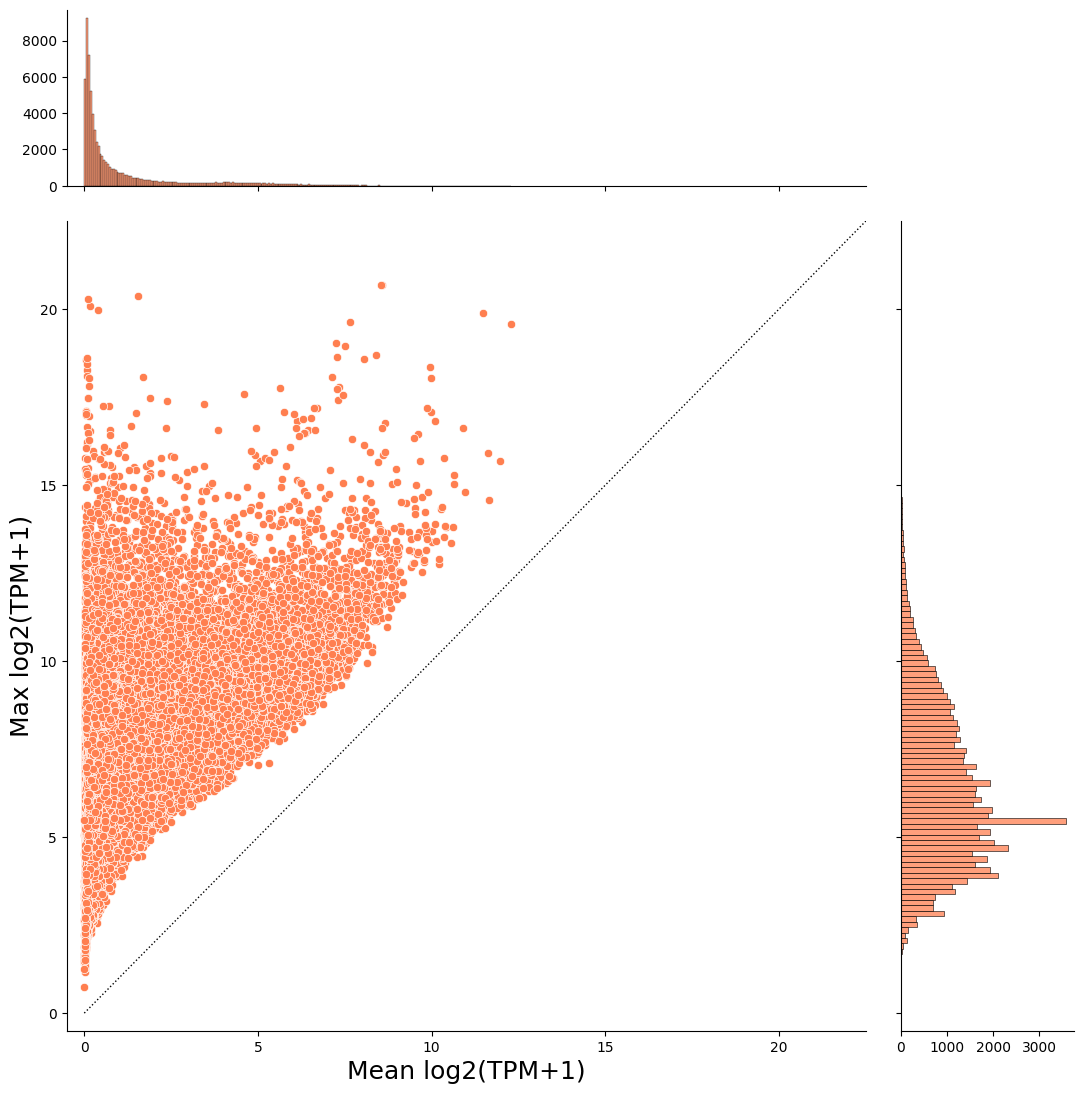

In [12]:
# プロモーターだけにして可視化してみる
fantabio_viz_pla = fantabio_row_stats_pla.select(
    "cre_id",
    "mean_log2(tpm+1)",
    "max_log2(tpm+1)",
    "max_log2(tpm+1) sample"
).to_pandas()

g = sns.jointplot(
    data=fantabio_viz_pla,
    x="mean_log2(tpm+1)",
    y="max_log2(tpm+1)",
    color="coral",
    height=11,
    ratio=4,
    marginal_ticks=True
)

plt.xlim(-0.5,22.5)
plt.ylim(-0.5,22.5)
plt.xlabel("Mean log2(TPM+1)", fontsize=18)
plt.ylabel("Max log2(TPM+1)", fontsize=18) 
# plt.axvline(x=20, color="black", linestyle=":")
# plt.axvline(x=40, color="black", linestyle=":")
# plt.axvline(x=60, color="black", linestyle=":")
# plt.axvline(x=80, color="black", linestyle=":")
# plt.axhline(y=20, color="black", linestyle=":")
# plt.axhline(y=40, color="black", linestyle=":")
# plt.axhline(y=60, color="black", linestyle=":")
# plt.axhline(y=80, color="black", linestyle=":")
g.ax_joint.plot([0, 22.5], [0, 22.5], color="black", linestyle=":", linewidth=1)

plt.show()

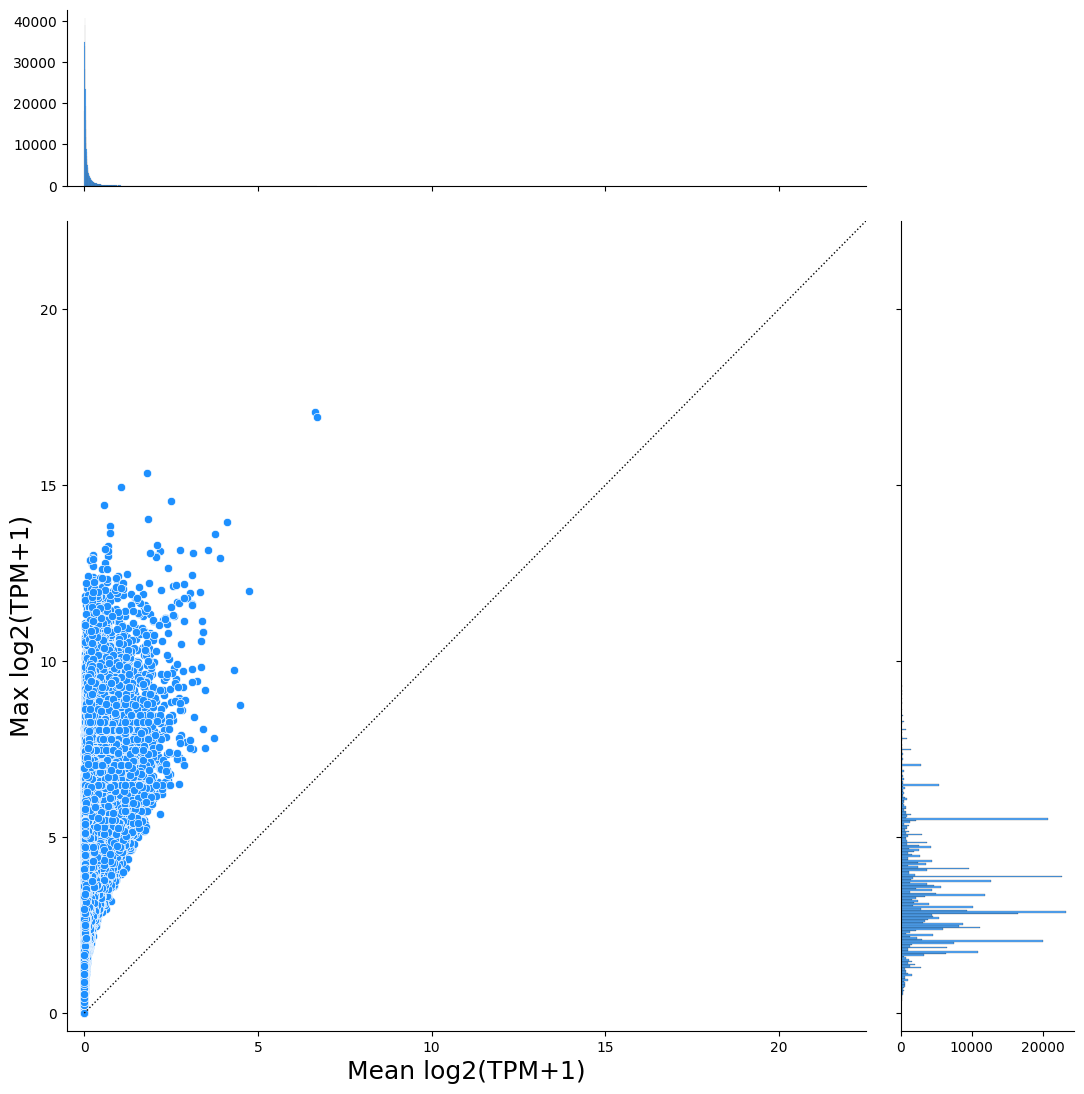

In [13]:
# エンハンサー (ELA) だけにして可視化してみる
fantabio_viz_ela = fantabio_row_stats_ela.select(
    "cre_id",
    "mean_log2(tpm+1)",
    "max_log2(tpm+1)",
    "max_log2(tpm+1) sample"
).to_pandas()

g = sns.jointplot(
    data=fantabio_viz_ela,
    x="mean_log2(tpm+1)",
    y="max_log2(tpm+1)",
    color="dodgerblue",
    height=11,
    ratio=4,
    marginal_ticks=True
)

plt.xlim(-0.5,22.5)
plt.ylim(-0.5,22.5)
plt.xlabel("Mean log2(TPM+1)", fontsize=18)
plt.ylabel("Max log2(TPM+1)", fontsize=18) 
# plt.axvline(x=20, color="black", linestyle=":")
# plt.axvline(x=40, color="black", linestyle=":")
# plt.axvline(x=60, color="black", linestyle=":")
# plt.axvline(x=80, color="black", linestyle=":")
# plt.axhline(y=20, color="black", linestyle=":")
# plt.axhline(y=40, color="black", linestyle=":")
# plt.axhline(y=60, color="black", linestyle=":")
# plt.axhline(y=80, color="black", linestyle=":")
g.ax_joint.plot([0, 22.5], [0, 22.5], color="black", linestyle=":", linewidth=1)

plt.show()

---

## Expression specificity（Polars）

元のセルは変更せず、この節を末尾に追加した。`fantabio_tpm`、`fantabio_sample_metadata`、
`fantabio_sample_cell`、`fantabio_sample_cell_line`、`fantabio_sample_uberon`、
`fantabio_bed_select`、`fantabio_row_stats` をそのまま利用する。前の可視化セルを再実行する必要はないが、
これらの DataFrame を作るセルは先に実行する。

**重要：既存の `fantabio_tpm` は名前に反して `log2(TPM+1)` に変換済み。**
追加処理は各サンプルの値を `2**x - 1` で線形値に戻してから集約する。
`mean_log2(tpm+1)`、`max_log2(tpm+1)` 等は entropy の入力に含めない。
巨大な線形行列を別途全件保持するのではなく、計算中の行ブロックのみを復元する。
元の `fantabio_tpm` と元の図は変わらない。復元は浮動小数点精度の範囲であり、
読み込み時の欠損・丸めによって失われた情報は復元できない。

本節の指標は前の回答で定義した **empirical Shannon entropy に基づく specificity** であり、
Chao–Shen 補正版ではない。指定された FC-R2 の R script との一致を保証する移植ではない。
ここでの `tpm` は元の notebook の命名を引き継いだ列名であり、単位を再定義しない。

比較集合は **既存の分類 × sample type × Protocol Name × condition** で分ける。
各比較集合（`panel`）につき、各 CRE に1つの specificity を与える。
異なる panel の値を単純に同一尺度の順位として比較しない。

**このファイルの新規セルは未実行。元のセルの出力はアップロード時のものを保持した。**
実データの gzip/BED は添付されていないため、ユーザー環境の既存パスから読み込む。
作成環境では Polars が利用できなかったため、構文・notebook形式・NumPy/SciPyによる参照式の検証を実施し、
実際の Polars 実装の照合テストは以下のセルに同梱した。

### 1. 計算設定

まず既定値で探索的に計算できる。`SPECIFICITY_REQUIRE_REVIEWED=False` は、
処理条件未確認のサンプルも含める設定であり、未処理・正常状態への自動分類ではない。
出版・最終解析では description と元レコードを確認し、次の対応表で採用条件を明示する。
`True` にすると条件未確認のサンプルがある場合は停止する。

`SPECIFICITY_UNIT_MODE="biosample"` は同じ BioSample accession の測定を先に平均し、
次にそのような単位を等重みで集約する設定。同じ accession を同一試料の再測定とみなす実装上の仮定であり、
独立した donor／biological replicate を自動同定する処理ではない。ID欠損時は Source Name 単位に分け、
その件数を記録する。ライブラリーを等重みにする場合は `"library"` を指定する。

In [ ]:
# 実計算に新たなファイルやCLI scriptは不要。既存のDataFrameを使う。
SPECIFICITY_INPUT_SCALE = "log2p1"  # 元notebookのfantabio_tpmに対応。自動判定しない。
SPECIFICITY_AGGREGATE = "mean"     # 感度分析には "median"
SPECIFICITY_UNIT_MODE = "biosample"  # または "library"
SPECIFICITY_ROW_BATCH_SIZE = 4096
SPECIFICITY_MIN_UNITS_PER_GROUP = 1
SPECIFICITY_DETECTION_THRESHOLD = 0.0  # 検出は線形値 > threshold。entropy自体は閾値処理しない。
SPECIFICITY_REQUIRE_REVIEWED = False
SPECIFICITY_KEEP_GROUP_EXPRESSION = True  # 群集約行列もDataFrameとして残す。メモリ節約時はFalse。
SPECIFICITY_PANEL_TO_INSPECT = None       # Noneなら計算済みpanelの辞書順の先頭を表示。
SPECIFICITY_PLOT = False
SPECIFICITY_SAVE_RESULTS = False
SPECIFICITY_SAVE_GROUP_EXPRESSION = False
SPECIFICITY_OUTPUT_DIR = pathlib.Path("./Output/fantabio_specificity") / Execute_date

print(f"Polars: {pl.__version__}")
print("入力は既存の log2(TPM+1) DataFrame。計算時に線形値へ戻します。")

### 2. 既存のサンプル分類と、正しい ontology ID 列を対応させる

元notebookの保存された出力から、次の列対応を確認した。

| 既存のDataFrame | ラベル列 | 対応するID列 |
|---|---|---|
| `fantabio_sample_cell` | `Characteristics [CL term]` | `Term Accession Number` |
| `fantabio_sample_cell_line` | `Characteristics [cell line]` | `Term Accession Number_duplicated_0` |
| `fantabio_sample_uberon` | `Characteristics [tissue]` | `Term Accession Number_duplicated_2` |

`_duplicated_1` は EFO の欄なので、tissue のIDとして使わない。
下の関数は suffix を固定せず、SDRFの列順から対応する accession 列を選ぶ。

CL の分類は元notebookと同じ「CL termあり、cell lineなし」であり、
全てが primary cell だと仮定しない。sample type の違いは別の panel にする。
一つの試料が CL と tissue の両方に出現しても、別の panel として計算する。
同じ panel 内で同じ試料を複数群へ重複計上することは許可しない。
ID欠損、複数ID、未対応の形式は勝手に補完せず、除外理由に残す。

In [ ]:
from __future__ import annotations

import math
import warnings
import polars as pl


def _required_columns(df: pl.DataFrame, names: list[str], label: str) -> None:
    missing = sorted(set(names) - set(df.columns))
    if missing:
        raise ValueError(f"{label}: 必要な列がありません: {missing}")


def _text(column: str) -> pl.Expr:
    """SDRF の文字列を整形する。null を推測して ontology を補完しない。"""
    value = pl.col(column).cast(pl.String).str.strip_chars()
    return pl.when(
        value.is_null() | value.str.to_lowercase().is_in(["", "na", "n/a", "null", "none", "-"])
    ).then(pl.lit(None, dtype=pl.String)).otherwise(value)


def _accession_after(metadata: pl.DataFrame, characteristic: str) -> str:
    """SDRF の列順から、その characteristic に属する accession 列を特定する。"""
    columns = metadata.columns
    start = columns.index(characteristic) + 1
    candidates = []
    for name in columns[start:]:
        if name.startswith("Characteristics [") or name == "Protocol Name":
            break
        if name.startswith("Term Accession Number"):
            candidates.append(name)
    if len(candidates) != 1:
        raise ValueError(f"{characteristic}: accession 列を一意に特定できません: {candidates}")
    return candidates[0]


def build_specificity_metadata(
    metadata: pl.DataFrame,
    sample_sets: dict[str, pl.DataFrame],
    expression: pl.DataFrame,
) -> tuple[pl.DataFrame, pl.DataFrame]:
    """既存の3分類を使い、sample × 分類の対応表と列対応を返す。"""
    required = [
        "Source Name", "Comment [biosample_id]", "Characteristics [organism]",
        "Characteristics [sample type]", "Characteristics [description]", "Protocol Name",
        "Characteristics [CL term]", "Characteristics [cell line]", "Characteristics [tissue]",
    ]
    _required_columns(metadata, required, "fantabio_sample_metadata")
    _required_columns(expression, ["cre_id"], "fantabio_tpm")
    if metadata["Source Name"].null_count() or metadata["Source Name"].n_unique() != metadata.height:
        raise ValueError("Source Name に null または重複があります。metadata を確認してください。")

    settings = [
        ("cell_CL", "Characteristics [CL term]", "CL", r"CL[:_][0-9]+"),
        ("cell_line", "Characteristics [cell line]", "Cellosaurus", r"CVCL[:_][A-Za-z0-9]+"),
        ("tissue", "Characteristics [tissue]", "UBERON", r"UBERON[:_][0-9]+"),
    ]
    frames, mapping = [], []
    for kind, label_col, vocabulary, accession_pattern in settings:
        accession_col = _accession_after(metadata, label_col)
        mapping.append({
            "sample_category": kind, "label_column": label_col,
            "accession_column": accession_col, "vocabulary": vocabulary,
        })
        subset = sample_sets[kind]
        _required_columns(subset, ["Source Name"], kind)
        if subset["Source Name"].null_count() or subset["Source Name"].n_unique() != subset.height:
            raise ValueError(f"{kind}: Source Name が一意ではありません。")
        unknown = set(subset["Source Name"].to_list()) - set(metadata["Source Name"].to_list())
        if unknown:
            raise ValueError(f"{kind}: 元 metadata にない Source Name: {sorted(unknown)[:10]}")
        part = metadata.join(subset.select("Source Name"), on="Source Name", how="semi")
        # 単一 CURIE、underscore ID、またはその ID で終わる URL のみを受け付ける。
        # 複数IDの文字列から最後のIDだけを勝手に採用しない。
        canonical_id = _text(accession_col).str.extract(
            rf"^(?:https?://[^\s,;|]+/)?({accession_pattern})$", 1
        ).str.replace("_", ":")
        frames.append(part.select(
            _text("Source Name").alias("sample_id"),
            _text("Comment [biosample_id]").alias("biosample_id"),
            _text("Characteristics [organism]").alias("organism"),
            _text("Characteristics [sample type]").alias("sample_type"),
            _text("Characteristics [description]").alias("description"),
            _text("Protocol Name").alias("protocol"),
            pl.lit(kind).alias("sample_category"),
            _text(label_col).alias("group_label"),
            _text(accession_col).alias("raw_accession"),
            canonical_id.alias("group_id"),
        ))
    if not any(frame.height for frame in frames):
        raise ValueError("既存の3分類にサンプルがありません。")
    candidates = pl.concat(frames, how="vertical").with_columns(
        pl.col("sample_id").is_in(expression.columns).alias("in_expression"),
        pl.lit("unreviewed").alias("condition"),
        pl.lit(True).alias("include"),
        pl.lit(False).alias("condition_reviewed"),
        # 確認用の候補抽出にすぎず、陽性/陰性とも処理条件の確定には使わない。
        pl.col("description").fill_null("").str.contains(
            r"(?i)(knock.?down|knock.?out|\bsiRNA\b|\bshRNA\b|\bASO\b|"
            r"treated|treatment|stimulat|heat|shock|infect|differenti|"
            r"\b[0-9]+[ -]?(?:h|hr|hrs|hours?|min|minutes?|days?|weeks?)\b)"
        ).alias("description_review_flag"),
    ).with_columns(
        pl.when(pl.col("sample_id").is_null()).then(pl.lit("missing_sample_id"))
        .when(~pl.col("in_expression")).then(pl.lit("not_in_expression"))
        .when(pl.col("organism").fill_null("") != "Homo sapiens").then(pl.lit("not_human"))
        .when(pl.col("group_id").is_null()).then(pl.lit("missing_or_invalid_accession"))
        .when(pl.col("protocol").is_null()).then(pl.lit("missing_protocol"))
        .when(pl.col("sample_type").is_null()).then(pl.lit("missing_sample_type"))
        .otherwise(pl.lit(None, dtype=pl.String)).alias("exclusion_reason")
    )
    if candidates.select(pl.struct("sample_category", "sample_id").is_duplicated().any()).item():
        raise ValueError("同じ分類でサンプルが重複しています。")
    return candidates, pl.DataFrame(mapping)


def prepare_specificity_manifest(
    candidates: pl.DataFrame,
    overrides: pl.DataFrame | None = None,
    *,
    unit_mode: str = "biosample",
    require_reviewed: bool = False,
) -> tuple[pl.DataFrame, pl.DataFrame]:
    """Polars の対応表を準備。分類・sample type・protocol・condition ごとに比較集合を分離。"""
    if unit_mode not in {"biosample", "library"}:
        raise ValueError("unit_mode は 'biosample' または 'library' です。")
    audit = candidates.clone()
    if overrides is not None and overrides.height:
        _required_columns(overrides, ["sample_id"], "overrides")
        allowed = {"sample_id", "include", "condition", "condition_reviewed"}
        if set(overrides.columns) - allowed:
            raise ValueError(f"overrides の未対応列: {sorted(set(overrides.columns) - allowed)}")
        if overrides["sample_id"].null_count() or overrides["sample_id"].n_unique() != overrides.height:
            raise ValueError("overrides の sample_id に null または重複があります。")
        unknown = set(overrides["sample_id"].to_list()) - set(audit["sample_id"].to_list())
        if unknown:
            raise ValueError(f"overrides に分類対象外の sample_id があります: {sorted(unknown)[:10]}")
        changed = [name for name in overrides.columns if name != "sample_id"]
        if changed:
            audit = audit.join(
                overrides.rename({name: f"__override_{name}" for name in changed}),
                on="sample_id", how="left", validate="m:1",
            ).with_columns([
                pl.coalesce(f"__override_{name}", name).alias(name) for name in changed
            ]).drop([f"__override_{name}" for name in changed])
    for column in ["include", "condition_reviewed"]:
        if audit.schema[column] != pl.Boolean or audit[column].null_count():
            raise ValueError(f"{column} は null のない Boolean 列にしてください。")
    audit = audit.with_columns(_text("condition").alias("condition")).with_columns(
        pl.when(~pl.col("include")).then(pl.lit("excluded_by_user"))
        .when(pl.col("condition").is_null()).then(pl.lit("missing_condition"))
        .otherwise(pl.col("exclusion_reason")).alias("exclusion_reason")
    )
    manifest = audit.filter(pl.col("exclusion_reason").is_null())
    if manifest.is_empty():
        raise ValueError("計算に使えるサンプルがありません。audit を確認してください。")
    invalid_review = manifest.filter(pl.col("condition_reviewed") & (pl.col("condition") == "unreviewed"))
    if invalid_review.height:
        raise ValueError("condition_reviewed=True の行には、確認した condition を設定してください。")
    n_unreviewed = manifest.filter(~pl.col("condition_reviewed"))["sample_id"].n_unique()
    if n_unreviewed:
        message = (
            f"{n_unreviewed} samples の処理条件は未確認です。結果は探索的な比較であり、"
            "未処理状態の特異性ではありません。description と元データを確認してください。"
        )
        if require_reviewed:
            raise ValueError(message)
        warnings.warn(message, UserWarning, stacklevel=2)
    # 区切り文字を含む値を曖昧な panel ID にしない。
    panel_cols = ["sample_category", "sample_type", "protocol", "condition"]
    if manifest.select(pl.any_horizontal([
        pl.col(name).str.contains(" | ", literal=True) for name in panel_cols
    ]).any()).item():
        raise ValueError("panel に用いる値に ' | ' が含まれています。値を整理してください。")
    manifest = manifest.with_columns(
        pl.concat_str(panel_cols, separator=" | ").alias("panel"),
        (
            pl.when(pl.col("biosample_id").is_not_null())
            .then(pl.concat_str(pl.lit("biosample:"), pl.col("biosample_id")))
            .otherwise(pl.concat_str(pl.lit("library:"), pl.col("sample_id")))
            if unit_mode == "biosample"
            else pl.concat_str(pl.lit("library:"), pl.col("sample_id"))
        ).alias("unit_id"),
        pl.lit(unit_mode).alias("unit_mode"),
        (pl.col("biosample_id").is_null() & pl.lit(unit_mode == "biosample")).alias("unit_id_fallback"),
    ).sort(["panel", "group_id", "unit_id", "sample_id"])
    return manifest, audit

In [ ]:
fantabio_specificity_sample_sets = {
    "cell_CL": fantabio_sample_cell,
    "cell_line": fantabio_sample_cell_line,
    "tissue": fantabio_sample_uberon,
}
fantabio_specificity_candidates, fantabio_specificity_column_mapping = build_specificity_metadata(
    fantabio_sample_metadata,
    fantabio_specificity_sample_sets,
    fantabio_tpm,
)

display(fantabio_specificity_column_mapping)
display(
    fantabio_specificity_candidates.group_by(["sample_category", "sample_type", "protocol"])
    .agg(
        pl.col("sample_id").n_unique().alias("n_libraries"),
        pl.col("group_id").drop_nulls().n_unique().alias("n_groups_with_id"),
        pl.col("description_review_flag").sum().alias("n_description_review_flags"),
        pl.col("exclusion_reason").is_not_null().sum().alias("n_excluded"),
    ).sort(["sample_category", "sample_type", "protocol"])
)

# 元notebookのどの分類にも入らないサンプルも可視化しておく。
fantabio_specificity_unassigned_samples = fantabio_sample_metadata.filter(
    ~pl.col("Source Name").is_in(
        fantabio_specificity_candidates["sample_id"].unique().to_list()
    )
)
print(f"3分類の対象外: {fantabio_specificity_unassigned_samples.height} metadata rows")
display(fantabio_specificity_unassigned_samples.head(10))

In [ ]:
# flagは確認候補であり、Falseが「未処理」を意味するわけではない。
# flagだけで自動除外もしない。descriptionの全文を必要に応じて参照する。
fantabio_specificity_review_table = fantabio_specificity_candidates.select(
    "sample_id", "biosample_id", "sample_category", "sample_type", "protocol",
    "group_id", "group_label", "description", "description_review_flag", "exclusion_reason",
)
display(
    fantabio_specificity_review_table.filter(
        pl.col("description_review_flag") | pl.col("exclusion_reason").is_not_null()
    ).head(30)
)
# 例: 特定の細胞株について全サンプルを確認
# display(fantabio_specificity_review_table.filter(pl.col("group_id") == "CVCL_...".replace("_", ":")))

### 3. 採否と処理条件を DataFrame で編集する

対応表を外部ファイルに作り直す必要はない。以下の `fantabio_specificity_overrides` を編集する。
`sample_id` は `Source Name`／発現行列の列名であり、`Comment [biosample_id]` ではない。

空のまま実行すると既存3分類の採用可能サンプルを使った探索的解析になる。
確認した試料には `condition="control"` などと `condition_reviewed=True` を設定する。
`include=False` でその試料を除外できる。**unreviewed を一括で control に置換しない。**

例えば、実在するIDに置き換えた上で
`pl.DataFrame({"sample_id": [確認したID], "include": [True], "condition": ["control"], "condition_reviewed": [True]})`
を設定する。入力したIDが候補にない場合は停止する。

In [ ]:
fantabio_specificity_overrides = pl.DataFrame(schema={
    "sample_id": pl.String,
    "include": pl.Boolean,
    "condition": pl.String,
    "condition_reviewed": pl.Boolean,
})

fantabio_specificity_manifest, fantabio_specificity_metadata_audit = prepare_specificity_manifest(
    fantabio_specificity_candidates,
    fantabio_specificity_overrides,
    unit_mode=SPECIFICITY_UNIT_MODE,
    require_reviewed=SPECIFICITY_REQUIRE_REVIEWED,
)

display(
    fantabio_specificity_manifest.group_by("panel").agg(
        pl.col("sample_id").n_unique().alias("n_libraries"),
        pl.col("unit_id").n_unique().alias("n_units"),
        pl.col("group_id").n_unique().alias("n_groups"),
        (~pl.col("condition_reviewed")).sum().alias("n_unreviewed_libraries"),
        pl.col("unit_id_fallback").sum().alias("n_unit_id_fallback_libraries"),
    ).sort("panel")
)
display(
    fantabio_specificity_metadata_audit.filter(pl.col("exclusion_reason").is_not_null())
    .group_by(["sample_category", "exclusion_reason"]).len()
    .sort(["sample_category", "exclusion_reason"])
)

### 4. Polars で集約し、empirical entropy を計算する

群 $k$ 内の各単位 $u$ について、同一単位に属する測定の線形値をまず算術平均し $z_{gku}$ とする。
次に $x_{gk}=\operatorname{mean}_u(z_{gku})$ を求める（`aggregate="median"` の場合はこの段階のみ中央値）。

$$p_{gk}=\frac{x_{gk}}{\sum_{j=1}^{K}x_{gj}},\qquad
H_g=-\sum_{k=1}^{K}p_{gk}\ln p_{gk},\qquad
S_g=1-\frac{H_g}{\ln K}.$$

$K$ はその panel の採用群数で固定し、CREごとにゼロの群を取り除かない。
全群同値なら $S=0$、1群だけ正なら $S=1$、全群ゼロなら `null`。
`0 log(0)=0` とし、pseudo-count は加えない。null／NaN／Inf／負値は停止する。
既存の `read_csv(ignore_errors=True)` が生成した null も黙ってゼロにしない。

計算は既存の wide DataFrame の行ブロックに対する Polars expression で行う。
CRE × library の全行列を unpivot せず、pandasやNumPyへも変換しない。
`group_tpm` を保持する設定では、最終的な CRE × 群の行列分のメモリは必要になる。
SciPy は次の小規模照合テストにだけ使用する。

In [ ]:
def _validate_values(frame: pl.DataFrame, sample_columns: list[str], label: str) -> None:
    """検出されなかったゼロと、欠損・異常値を区別する。"""
    bad = frame.select(pl.any_horizontal([
        pl.col(name).is_null() | ~pl.col(name).is_finite() | (pl.col(name) < 0)
        for name in sample_columns
    ]).alias("invalid"))["invalid"]
    if bad.any():
        ids = frame.filter(bad)["cre_id"].head(5).to_list()
        raise ValueError(
            f"{label}: null/NaN/Inf/負値があります。CRE例={ids}。"
            "ゼロ補完は行いません。元の read_csv(ignore_errors=True) による null も確認してください。"
        )


def _shannon_from_groups(grouped: pl.DataFrame, detection_threshold: float) -> pl.DataFrame:
    """行=CRE、列=biosample種類の線形活性から、Polars式で S=1-H/log(K) を計算。"""
    group_columns = [name for name in grouped.columns if name != "cre_id"]
    k = len(group_columns)
    if k < 2:
        raise ValueError("Shannon specificity には2群以上必要です。")
    maximum = pl.max_horizontal([pl.col(name) for name in group_columns])
    stats = grouped.select(
        "cre_id",
        maximum.alias("max_group_tpm"),
        pl.sum_horizontal([(pl.col(name) > 0).cast(pl.UInt32) for name in group_columns]).alias("n_positive_groups"),
        pl.sum_horizontal([
            (pl.col(name) > detection_threshold).cast(pl.UInt32) for name in group_columns
        ]).alias("n_groups_above_threshold"),
        pl.concat_list([
            pl.when((pl.col(name) == maximum) & (maximum > 0))
            .then(pl.lit(name)).otherwise(pl.lit(None, dtype=pl.String))
            for name in group_columns
        ]).list.drop_nulls().alias("top_group_ids"),
    ).with_columns(
        pl.col("top_group_ids").list.len().alias("n_top_groups"),
        pl.when(pl.col("top_group_ids").list.len() == 1)
        .then(pl.col("top_group_ids").list.first())
        .otherwise(pl.lit(None, dtype=pl.String)).alias("top_group_id"),
        pl.lit(k, dtype=pl.UInt32).alias("n_groups"),
    )
    # 行最大値で scale して overflow を避ける。行内の比率 p は変わらない。
    scaled = grouped.with_columns(
        pl.when(maximum > 0).then(maximum).otherwise(1.0).alias("__scale")
    ).select("cre_id", *[
        (pl.col(name) / pl.col("__scale")).alias(name) for name in group_columns
    ]).with_columns(
        pl.sum_horizontal([pl.col(name) for name in group_columns]).alias("__sum")
    )
    probability = scaled.select([
        (pl.col(name) / pl.when(pl.col("__sum") > 0).then(pl.col("__sum")).otherwise(1.0)).alias(name)
        for name in group_columns
    ])
    # 0*log(0) の項を明示的に0とする。pseudo-count は加えない。
    h = probability.select(pl.sum_horizontal([
        pl.when(pl.col(name) > 0)
        .then(-pl.col(name) * pl.col(name).log())
        .otherwise(0.0)
        for name in group_columns
    ]).alias("entropy"))["entropy"]
    return stats.with_columns(h).with_columns(
        pl.when(pl.col("max_group_tpm") > 0).then(pl.col("entropy"))
        .otherwise(pl.lit(None, dtype=pl.Float64)).alias("entropy"),
        pl.when(pl.col("max_group_tpm") > 0).then(pl.lit("ok"))
        .otherwise(pl.lit("all_group_values_zero")).alias("status"),
    ).with_columns(
        (pl.col("entropy") / math.log(k)).clip(0.0, 1.0).alias("normalized_entropy"),
        (1.0 - pl.col("entropy") / math.log(k)).clip(0.0, 1.0).alias("specificity"),
        (pl.col("max_group_tpm") + 1.0).log(base=2).alias("max_group_log2(tpm+1)"),
    )


def calculate_cre_specificity_polars(
    expression: pl.DataFrame,
    manifest: pl.DataFrame,
    *,
    input_scale: str = "log2p1",
    aggregate: str = "mean",
    row_batch_size: int = 4096,
    detection_threshold: float = 0.0,
    min_units_per_group: int = 1,
    keep_group_expression: bool = True,
    verbose: bool = True,
) -> dict:
    """既存 wide DataFrame を入力し、Polars DataFrame の結果を返す。

    - input_scale='log2p1': 各サンプルを 2**x-1 に戻してから集約。
    - 同一 panel/group/unit 内は mean、その後 unit 間を mean または median。
    - panel は別々に計算。群を均等に扱い、CREごとにゼロ群を除外しない。
    - full unpivot や pandas/NumPy への変換は行わない。
    """
    if not isinstance(expression, pl.DataFrame) or not isinstance(manifest, pl.DataFrame):
        raise TypeError("expression と manifest は polars.DataFrame を渡してください。")
    if input_scale not in {"log2p1", "linear"}:
        raise ValueError("input_scale は 'log2p1' または 'linear' です。")
    if aggregate not in {"mean", "median"}:
        raise ValueError("aggregate は 'mean' または 'median' です。")
    if not isinstance(row_batch_size, int) or row_batch_size < 1:
        raise ValueError("row_batch_size は1以上の整数です。")
    if not isinstance(min_units_per_group, int) or min_units_per_group < 1:
        raise ValueError("min_units_per_group は1以上の整数です。")
    if not math.isfinite(detection_threshold) or detection_threshold < 0:
        raise ValueError("detection_threshold は0以上の有限値です。")
    _required_columns(expression, ["cre_id"], "expression")
    _required_columns(manifest, [
        "sample_id", "panel", "group_id", "group_label", "unit_id", "sample_category",
        "sample_type", "protocol", "condition", "condition_reviewed", "unit_mode", "unit_id_fallback",
    ], "manifest")
    if expression.is_empty() or manifest.is_empty():
        raise ValueError("expression または manifest が空です。")
    if expression["cre_id"].null_count() or expression["cre_id"].n_unique() != expression.height:
        raise ValueError("cre_id に null または重複があります。")
    for name in ["sample_id", "panel", "group_id", "unit_id", "condition_reviewed"]:
        if manifest[name].null_count():
            raise ValueError(f"manifest の {name} に null があります。")
    if manifest.select(pl.struct("panel", "sample_id").is_duplicated().any()).item():
        raise ValueError("同じ panel に同じ sample_id を複数回割り当てることはできません。")
    # 同一試料IDを同じ比較集合で別々の種類に割り当てていないか確認。
    conflicts = manifest.group_by(["panel", "unit_id"]).agg(
        pl.col("group_id").n_unique().alias("n_groups")
    ).filter(pl.col("n_groups") > 1)
    if conflicts.height:
        raise ValueError(f"同じ panel/unit が複数群に属しています。metadata を確認してください:\n{conflicts.head(5)}")
    missing = sorted(set(manifest["sample_id"].to_list()) - set(expression.columns))
    if missing:
        raise ValueError(f"matrix にない sample_id: {missing[:10]}")
    sample_columns = sorted(set(manifest["sample_id"].to_list()))
    nonnumeric = [name for name in sample_columns if not expression.schema[name].is_numeric()]
    if nonnumeric:
        raise TypeError(f"発現列が数値型ではありません: {nonnumeric[:10]}")

    group_metadata = manifest.group_by(["panel", "group_id"]).agg(
        pl.col("group_label").drop_nulls().unique().sort().alias("group_labels"),
        pl.col("sample_id").n_unique().alias("n_libraries"),
        pl.col("unit_id").n_unique().alias("n_units"),
        pl.col("unit_id_fallback").sum().alias("n_unit_id_fallback_libraries"),
        pl.col("condition_reviewed").all().alias("condition_reviewed"),
        *[pl.col(name).first().alias(name) for name in [
            "sample_category", "sample_type", "protocol", "condition", "unit_mode"
        ]],
    ).sort(["panel", "group_id"]).with_columns(
        (pl.col("n_units") >= min_units_per_group).alias("included_group")
    )
    panel_qc = group_metadata.group_by("panel").agg(
        pl.len().alias("n_groups_before_filter"),
        pl.col("included_group").sum().alias("n_groups"),
        pl.col("n_libraries").filter(pl.col("included_group")).sum().alias("n_libraries"),
        pl.col("n_units").filter(pl.col("included_group")).sum().alias("n_units"),
    ).with_columns((pl.col("n_groups") >= 2).alias("calculated")).sort("panel")
    usable = group_metadata.filter(pl.col("included_group")).join(
        panel_qc.filter(pl.col("calculated")).select("panel"), on="panel", how="semi"
    )
    if usable.is_empty():
        raise ValueError(f"2群以上残る panel がありません。min_units_per_group と metadata を確認してください:\n{panel_qc}")
    used_manifest = manifest.join(usable.select("panel", "group_id"), on=["panel", "group_id"], how="semi")
    all_scores, group_frames = [], {}
    for panel in sorted(used_manifest["panel"].unique().to_list()):
        panel_manifest = used_manifest.filter(pl.col("panel") == panel)
        panel_info = usable.filter(pl.col("panel") == panel).sort("group_id")
        groups = panel_info["group_id"].to_list()
        sample_names = sorted(set(panel_manifest["sample_id"].to_list()))
        # Python で扱うのは小さな metadata のみ。CRE × sample の値は Polars で処理。
        units_by_group = {}
        unit_samples = {}
        for row in panel_manifest.iter_rows(named=True):
            key = (row["group_id"], row["unit_id"])
            unit_samples.setdefault(key, []).append(row["sample_id"])
        unit_expressions = []
        for index, (key, names) in enumerate(sorted(unit_samples.items())):
            unit_column = f"__unit_{index:06d}"
            units_by_group.setdefault(key[0], []).append(unit_column)
            unit_expressions.append(
                pl.mean_horizontal([pl.col(name) for name in names], ignore_nulls=False).alias(unit_column)
            )
        group_expressions, detection_expressions = [], []
        for group in groups:
            values = [pl.col(name) for name in units_by_group[group]]
            value = (
                pl.mean_horizontal(values, ignore_nulls=False)
                if aggregate == "mean"
                else pl.concat_list(values).list.median()
            )
            group_expressions.append(value.alias(group))
            detection_expressions.append(pl.mean_horizontal([
                (value > detection_threshold).cast(pl.Float64) for value in values
            ], ignore_nulls=False).alias(group))
        reviewed = bool(panel_manifest["condition_reviewed"].all())
        panel_status = "condition_reviewed" if reviewed else "exploratory_unreviewed"
        if verbose:
            print(f"{panel}: {len(sample_names)} libraries, {len(unit_samples)} units, {len(groups)} groups")
        panel_scores, panel_grouped = [], []
        selected = expression.select("cre_id", *sample_names)
        for chunk in selected.iter_slices(n_rows=row_batch_size):
            _validate_values(chunk, sample_names, "入力")
            if input_scale == "log2p1":
                linear = chunk.select("cre_id", *[
                    (pl.lit(2.0).pow(pl.col(name).cast(pl.Float64)) - 1.0).alias(name)
                    for name in sample_names
                ])
            else:
                linear = chunk.select("cre_id", *[pl.col(name).cast(pl.Float64) for name in sample_names])
            _validate_values(linear, sample_names, "線形値への変換後")
            units = linear.select("cre_id", *unit_expressions)
            grouped = units.select("cre_id", *group_expressions)
            _validate_values(grouped, groups, "集約後")
            detected = units.select(detection_expressions)
            scores = _shannon_from_groups(grouped, detection_threshold)
            # 同率最大の場合は特定の1群を選ばず、support は null にする。
            scores = scores.with_columns(
                pl.coalesce([
                    pl.when(pl.col("top_group_id") == group)
                    .then(pl.lit(detected[group])).otherwise(pl.lit(None, dtype=pl.Float64))
                    for group in groups
                ]).alias("top_group_detection_fraction"),
                linear.select(pl.max_horizontal([pl.col(name) for name in sample_names]).alias("max_sample_tpm"))["max_sample_tpm"],
                pl.lit(panel).alias("panel"),
                pl.lit(len(sample_names), dtype=pl.UInt32).alias("n_libraries"),
                pl.lit(len(unit_samples), dtype=pl.UInt32).alias("n_units"),
                pl.lit(aggregate).alias("aggregate"),
                pl.lit(input_scale).alias("input_scale"),
                pl.lit(detection_threshold).alias("detection_threshold"),
                pl.lit(panel_status).alias("analysis_status"),
            )
            panel_scores.append(scores)
            if keep_group_expression:
                panel_grouped.append(grouped)
        all_scores.append(pl.concat(panel_scores, how="vertical", rechunk=False))
        if keep_group_expression:
            group_frames[panel] = pl.concat(panel_grouped, how="vertical", rechunk=False)
    scores = pl.concat(all_scores, how="vertical", rechunk=False).join(
        group_metadata.select(
            "panel", pl.col("group_id").alias("top_group_id"),
            pl.col("group_labels").list.join(" / ").alias("top_group_label"),
            pl.col("n_units").alias("top_group_n_units"),
            pl.col("n_libraries").alias("top_group_n_libraries"),
        ), on=["panel", "top_group_id"], how="left", validate="m:1",
    )
    return {
        "scores": scores,
        "group_tpm": group_frames,
        "group_metadata": group_metadata,
        "manifest": used_manifest,
        "panel_qc": panel_qc,
    }

### 5. 実装の照合テスト（合成データ）

このセルは実データを使用しない。Polars の実装を実行し、SciPy と数値を照合する。
不均等な反復数、log逆変換、平均／中央値、同一BioSampleの複数測定、ゼロ、同率最大、
欠損・異常値、重複ID、1群しかないpanel、ランダムな疎行列を確認する。
例外やFAILが出た場合は実データの計算を進めない。

作成環境では Polars 不在のため、このテスト自体は未実行。ユーザー環境でこのセルを先に実行する。
SciPyがなければ、使用中のkernelの環境に追加する（インストールを自動実行しない）。

In [ ]:
def run_specificity_self_test() -> pl.DataFrame:
    """小規模な合成データで、実際の Polars 実装を SciPy と照合する。"""
    import numpy as np
    from scipy.stats import entropy as scipy_entropy

    checks = []

    def make_manifest(sample_ids, group_ids, unit_ids=None, panel="synthetic"):
        n = len(sample_ids)
        return pl.DataFrame({
            "sample_id": sample_ids, "group_id": group_ids,
            "group_label": group_ids, "unit_id": unit_ids or sample_ids,
            "panel": [panel] * n, "sample_category": ["cell_CL"] * n,
            "sample_type": ["primary cell"] * n, "protocol": ["synthetic"] * n,
            "condition": ["control"] * n, "condition_reviewed": [True] * n,
            "unit_mode": ["biosample"] * n, "unit_id_fallback": [False] * n,
        })

    def check(name, condition):
        if not condition:
            raise AssertionError(name)
        checks.append({"check": name, "result": "PASS"})

    def must_fail(name, callable_):
        try:
            callable_()
        except (ValueError, TypeError):
            check(name, True)
        else:
            raise AssertionError(f"例外が発生しませんでした: {name}")

    sample_ids = ["s1", "s2", "s3", "s4", "s5", "s6"]
    group_ids = ["CL:1", "CL:1", "CL:1", "CL:2", "CL:2", "CL:3"]
    cre_ids = ["uniform", "exclusive", "two_groups", "zero", "outlier"]
    values = np.array([
        [1, 1, 1, 1, 1, 1],
        [10, 10, 10, 0, 0, 0],
        [2, 2, 2, 2, 2, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 90, 10, 10, 0],
    ], dtype=float)
    frame = pl.DataFrame({"cre_id": cre_ids, **{s: values[:, i] for i, s in enumerate(sample_ids)}})
    manifest = make_manifest(sample_ids, group_ids)
    kwargs = {"input_scale": "linear", "verbose": False, "row_batch_size": 2}
    result = calculate_cre_specificity_polars(frame, manifest, **kwargs)
    expected = np.column_stack([values[:, :3].mean(1), values[:, 3:5].mean(1), values[:, 5]])
    np.testing.assert_allclose(result["group_tpm"]["synthetic"].select("CL:1", "CL:2", "CL:3").to_numpy(), expected)
    check("Unequal library counts: group means", True)
    expected_h = np.full(len(cre_ids), np.nan)
    positive = expected.sum(1) > 0
    expected_h[positive] = scipy_entropy(expected[positive], axis=1)
    got = result["scores"].sort("cre_id")
    order = np.argsort(cre_ids)
    np.testing.assert_allclose(got["entropy"].to_numpy(), expected_h[order], atol=1e-12, equal_nan=True)
    np.testing.assert_allclose(got["specificity"].to_numpy(), (1 - expected_h / np.log(3))[order], atol=1e-12, equal_nan=True)
    check("Polars entropy and specificity == SciPy", True)
    check("All-zero CRE has null specificity", result["scores"].filter(pl.col("cre_id") == "zero")["specificity"][0] is None)
    uniform = result["scores"].filter(pl.col("cre_id") == "uniform")
    check("Tied top groups are retained; no arbitrary winner", uniform["n_top_groups"][0] == 3 and uniform["top_group_id"][0] is None)
    logged = frame.with_columns([(pl.col(s) + 1).log(base=2) for s in sample_ids])
    inverse = calculate_cre_specificity_polars(logged, manifest, input_scale="log2p1", verbose=False)
    np.testing.assert_allclose(
        inverse["scores"].sort("cre_id")["specificity"].to_numpy(), got["specificity"].to_numpy(),
        atol=1e-12, equal_nan=True,
    )
    check("Inverse log2(TPM+1) before aggregation", True)
    median = calculate_cre_specificity_polars(frame, manifest, aggregate="median", **kwargs)
    expected_median = np.column_stack([np.median(values[:, :3], axis=1), np.median(values[:, 3:5], axis=1), values[:, 5]])
    np.testing.assert_allclose(median["group_tpm"]["synthetic"].select("CL:1", "CL:2", "CL:3").to_numpy(), expected_median)
    check("Median aggregation", True)
    outlier = result["scores"].filter(pl.col("cre_id") == "outlier")
    check("Detection fraction counts units", np.isclose(outlier["top_group_detection_fraction"][0], 1 / 3))
    # 同じBioSampleを2回測定したunitと1回測定したunitを等重みにする。
    unit_frame = pl.DataFrame({"cre_id": ["u"], "a1": [0.0], "a2": [0.0], "b": [100.0], "c": [0.0]})
    unit_manifest = make_manifest(["a1", "a2", "b", "c"], ["G1", "G1", "G1", "G2"], ["A", "A", "B", "C"])
    unit_result = calculate_cre_specificity_polars(unit_frame, unit_manifest, **kwargs)
    check("Equal unit weights after within-BioSample averaging", unit_result["group_tpm"]["synthetic"]["G1"][0] == 50.0)
    # summary列をmetadataのsampleとして誤読しない。
    with_extra = frame.with_columns(pl.lit(-999.0).alias("mean_log2(tpm+1)"))
    ignored = calculate_cre_specificity_polars(with_extra, manifest, **kwargs)
    np.testing.assert_allclose(ignored["scores"].sort("cre_id")["specificity"].to_numpy(), got["specificity"].to_numpy(), equal_nan=True)
    check("Existing row-summary columns excluded", True)
    # 同じ値でもpanel間で混ぜない。1群しかないpanelはqcに残してskip。
    single = make_manifest(["s1"], ["CL:1"], panel="single_group")
    mixed = calculate_cre_specificity_polars(frame, pl.concat([manifest, single]), **kwargs)
    check("Single-group panel reported and skipped", mixed["panel_qc"].filter(pl.col("panel") == "single_group")["calculated"][0] == False)
    # 欠損、異常値、重複IDを黙って修正しない。
    for label, bad_value in [("null", None), ("NaN", float("nan")), ("Inf", float("inf")), ("negative", -1.0)]:
        bad = frame.with_columns(pl.lit(bad_value, dtype=pl.Float64).alias("s1"))
        must_fail(f"Reject {label}", lambda bad=bad: calculate_cre_specificity_polars(bad, manifest, **kwargs))
    duplicate = pl.concat([frame, frame.head(1)])
    must_fail("Reject duplicate CRE ID", lambda: calculate_cre_specificity_polars(duplicate, manifest, **kwargs))
    must_fail("Reject duplicate sample in a panel", lambda: calculate_cre_specificity_polars(frame, pl.concat([manifest, manifest.head(1)]), **kwargs))
    # thresholdは品質確認用であり、entropyの入力値を切り捨てない。
    high_threshold = calculate_cre_specificity_polars(frame, manifest, detection_threshold=100.0, **kwargs)
    np.testing.assert_allclose(high_threshold["scores"].sort("cre_id")["specificity"].to_numpy(), got["specificity"].to_numpy(), equal_nan=True)
    check("Detection threshold does not modify entropy", True)
    # ランダムな疎な行列でも同じ実装を照合する。
    rng = np.random.default_rng(123)
    random_values = rng.lognormal(size=(100, 6))
    random_values[rng.random((100, 6)) < 0.6] = 0
    random_frame = pl.DataFrame({"cre_id": [f"r{i:03d}" for i in range(100)], **{s: random_values[:, i] for i, s in enumerate(sample_ids)}})
    rr = calculate_cre_specificity_polars(random_frame, manifest, **kwargs)
    reference_groups = np.column_stack([random_values[:, :3].mean(1), random_values[:, 3:5].mean(1), random_values[:, 5]])
    rr_valid = reference_groups.sum(1) > 0
    rr_expected = np.full(100, np.nan)
    rr_expected[rr_valid] = 1 - scipy_entropy(reference_groups[rr_valid], axis=1) / np.log(3)
    np.testing.assert_allclose(rr["scores"].sort("cre_id")["specificity"].to_numpy(), rr_expected, atol=1e-12, equal_nan=True)
    check("Random sparse matrix == SciPy", True)
    return pl.DataFrame(checks)

In [ ]:
fantabio_specificity_test_results = run_specificity_self_test()
display(fantabio_specificity_test_results)

### 6. 実データについて計算する

`fantabio_specificity` は **1行=CRE × panel** の Polars DataFrame。
`fantabio_group_tpm` は **panel名 → CRE × 群の Polars DataFrame** の辞書。
`fantabio_group_metadata` は各群のID・ラベル・採用数。

群数が2未満になったpanelは計算せず `fantabio_specificity_panel_qc` に記録する。
少なくとも1つは2群以上のpanelが必要。最小単位数のフィルターは群全体に一度適用し、CREごとには変えない。

In [ ]:
fantabio_specificity_result = calculate_cre_specificity_polars(
    expression=fantabio_tpm,
    manifest=fantabio_specificity_manifest,
    input_scale=SPECIFICITY_INPUT_SCALE,
    aggregate=SPECIFICITY_AGGREGATE,
    row_batch_size=SPECIFICITY_ROW_BATCH_SIZE,
    detection_threshold=SPECIFICITY_DETECTION_THRESHOLD,
    min_units_per_group=SPECIFICITY_MIN_UNITS_PER_GROUP,
    keep_group_expression=SPECIFICITY_KEEP_GROUP_EXPRESSION,
)

fantabio_specificity = fantabio_specificity_result["scores"]
fantabio_group_tpm = fantabio_specificity_result["group_tpm"]
fantabio_group_metadata = fantabio_specificity_result["group_metadata"]
fantabio_specificity_used_manifest = fantabio_specificity_result["manifest"]
fantabio_specificity_panel_qc = fantabio_specificity_result["panel_qc"]

display(fantabio_specificity_panel_qc)
display(fantabio_specificity.head(10))

### 7. 既存の CRE 注釈・PLA／ELA と結合する

2,644個のサンプル列全てを再結合せず、既存の注釈と行要約だけを結合する。
既存の `fantabio_row_stats_bed`、`fantabio_row_stats_pla`、`fantabio_row_stats_ela` は上書きしない。
ここでの `max_group_log2(tpm+1)` は、線形値の群代表値を求めた後にlog変換した値。
元の `mean_log2(tpm+1)`（全ライブラリーのlog値の平均）とは意味が異なる。

In [ ]:
fantabio_specificity_bed = (
    fantabio_specificity
    .join(fantabio_bed_select, on="cre_id", how="left", validate="m:1")
    .join(
        fantabio_row_stats.select(
            "cre_id", "mean_log2(tpm+1)", "max_log2(tpm+1)", "max_log2(tpm+1) sample"
        ),
        on="cre_id", how="left", validate="m:1",
    )
)
fantabio_specificity_pla = fantabio_specificity_bed.filter(pl.col("fantabio_cre_class") == "PLA")
fantabio_specificity_ela = fantabio_specificity_bed.filter(pl.col("fantabio_cre_class") == "ELA")

display(
    fantabio_specificity_bed.group_by(["panel", "fantabio_cre_class"])
    .agg(
        pl.len().alias("n_cre"),
        pl.col("specificity").is_not_null().sum().alias("n_cre_with_specificity"),
        pl.col("specificity").median().alias("median_specificity"),
    ).sort(["panel", "fantabio_cre_class"])
)

### 8. DataFrame として絞り込む・群別の活性を見る

まず一つのpanelに絞る。異なるpanelの行を混ぜて単一のCREリストのように結合すると、CREごとに行が増える。
`top_group_ids` には同率最大の群を全て保存する。`top_group_id` は最大群が一つのときだけ値を持つ。
最大群が同率の場合、`top_group_detection_fraction` などの単一群向け列は `null`。
`top_group_detection_fraction` は、その最大群の**単位**のうち線形活性が閾値を上回る割合。

表示用の上位選択は計算を変更しない。specificityが高くても低活性・低再現性なら慎重に扱う。
下の unpivot は、表示する数CREの群集約値だけに限定している。

In [ ]:
_specificity_panels = sorted(fantabio_specificity["panel"].unique().to_list())
specificity_panel = SPECIFICITY_PANEL_TO_INSPECT or _specificity_panels[0]
if specificity_panel not in _specificity_panels:
    raise ValueError(f"未知のpanel: {specificity_panel}. 選択肢={_specificity_panels}")

fantabio_specificity_selected = fantabio_specificity_bed.filter(pl.col("panel") == specificity_panel)
print("表示するpanel:", specificity_panel)
display(
    fantabio_specificity_selected.select(
        "cre_id", "cre_name", "fantabio_cre_class", "specificity", "entropy", "n_groups",
        "max_group_tpm", "n_positive_groups", "top_group_id", "top_group_label",
        "top_group_n_units", "top_group_detection_fraction", "analysis_status",
    ).sort(["specificity", "max_group_tpm"], descending=[True, True], nulls_last=True).head(20)
)

group_info = fantabio_group_metadata.filter(
    (pl.col("panel") == specificity_panel) & pl.col("included_group")
)
display(group_info)
fantabio_specificity_example_expression = None
if specificity_panel in fantabio_group_tpm:
    _example_ids = (
        fantabio_specificity_selected.filter(pl.col("specificity").is_not_null())
        .sort(["specificity", "max_group_tpm"], descending=[True, True]).head(5)["cre_id"].to_list()
    )
    fantabio_specificity_example_expression = (
        fantabio_group_tpm[specificity_panel].filter(pl.col("cre_id").is_in(_example_ids))
        .unpivot(index="cre_id", variable_name="group_id", value_name="group_tpm")
        .join(group_info.select("group_id", "group_labels", "n_units", "n_libraries"),
              on="group_id", how="left", validate="m:1")
        .sort(["cre_id", "group_tpm"], descending=[False, True])
    )
    display(fantabio_specificity_example_expression.head(30))
else:
    print("群集約行列は保持していません。必要なら SPECIFICITY_KEEP_GROUP_EXPRESSION=True で再計算してください。")

### 9. 可視化（任意）

`SPECIFICITY_PLOT=True` のときのみ、選択したpanelのPLA・ELAについて、
横軸specificity、縦軸最大群活性のlog値を別々の図で描く。
計算結果はPolarsのまま保持し、描画時に必要な2列だけをNumPy配列にする。

In [ ]:
if SPECIFICITY_PLOT:
    for _cre_class in ["PLA", "ELA"]:
        _plot_data = fantabio_specificity_selected.filter(
            (pl.col("fantabio_cre_class") == _cre_class) & pl.col("specificity").is_not_null()
        ).select("specificity", "max_group_log2(tpm+1)")
        if _plot_data.is_empty():
            continue
        _fig, _ax = plt.subplots(figsize=(8, 6))
        _hex = _ax.hexbin(
            _plot_data["specificity"].to_numpy(),
            _plot_data["max_group_log2(tpm+1)"].to_numpy(),
            gridsize=65, mincnt=1,
        )
        _fig.colorbar(_hex, ax=_ax, label="Number of CREs")
        _ax.set(xlabel="Expression specificity (1 - H / log K)",
                ylabel="Max group log2(TPM+1)", xlim=(-0.02, 1.02),
                title=f"{_cre_class}\n{specificity_panel}")
        _fig.tight_layout()
        plt.show()

### 10. 保存（任意）と読み戻し

`SPECIFICITY_SAVE_RESULTS=True` のときだけ保存する。
List型の `top_group_ids`／`group_labels` を保持できる Parquet を使用する。
群集約行列は大きくなり得るため、保存は別の設定で明示的に有効にする。
同じ出力ディレクトリに再実行すると同名ファイルを更新するので、条件を変える際はディレクトリも変える。

In [ ]:
if SPECIFICITY_SAVE_RESULTS:
    import json
    import sys

    SPECIFICITY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fantabio_specificity_bed.write_parquet(SPECIFICITY_OUTPUT_DIR / "cre_specificity.parquet")
    fantabio_group_metadata.write_parquet(SPECIFICITY_OUTPUT_DIR / "group_metadata.parquet")
    fantabio_specificity_used_manifest.write_parquet(SPECIFICITY_OUTPUT_DIR / "used_manifest.parquet")
    fantabio_specificity_panel_qc.write_parquet(SPECIFICITY_OUTPUT_DIR / "panel_qc.parquet")
    fantabio_specificity_metadata_audit.write_parquet(SPECIFICITY_OUTPUT_DIR / "metadata_audit.parquet")
    fantabio_specificity_unassigned_samples.write_parquet(SPECIFICITY_OUTPUT_DIR / "unassigned_samples.parquet")
    _config = {
        "method": "empirical_Shannon", "specificity_formula": "1 - H / ln(K)",
        "input_scale": SPECIFICITY_INPUT_SCALE, "aggregate": SPECIFICITY_AGGREGATE,
        "unit_mode": SPECIFICITY_UNIT_MODE,
        "min_units_per_group": SPECIFICITY_MIN_UNITS_PER_GROUP,
        "detection_threshold": SPECIFICITY_DETECTION_THRESHOLD,
        "require_reviewed": SPECIFICITY_REQUIRE_REVIEWED,
        "row_batch_size": SPECIFICITY_ROW_BATCH_SIZE,
        "matrix_shape": list(fantabio_tpm.shape),
        "polars_version": pl.__version__, "python_version": sys.version,
        "execute_date": Execute_date,
        "panel_columns": ["sample_category", "sample_type", "protocol", "condition"],
        "overrides": fantabio_specificity_overrides.to_dicts(),
    }
    (SPECIFICITY_OUTPUT_DIR / "settings.json").write_text(
        json.dumps(_config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    if SPECIFICITY_SAVE_GROUP_EXPRESSION:
        _group_file_rows = []
        for _index, (_panel, _df) in enumerate(sorted(fantabio_group_tpm.items())):
            _filename = f"group_tpm_{_index:03d}.parquet"
            _df.write_parquet(SPECIFICITY_OUTPUT_DIR / _filename)
            _group_file_rows.append({"panel": _panel, "file": _filename})
        if _group_file_rows:
            pl.DataFrame(_group_file_rows).write_csv(SPECIFICITY_OUTPUT_DIR / "group_files.tsv", separator="\t")
    print("保存先:", SPECIFICITY_OUTPUT_DIR.resolve())

# 読み戻しの例（保存を実行した後に有効化）:
# fantabio_specificity_bed = pl.read_parquet(SPECIFICITY_OUTPUT_DIR / "cre_specificity.parquet")

### 出力の解釈と検証範囲

`entropy` は自然対数のShannon entropy、`normalized_entropy` は `entropy / ln(n_groups)`、
`specificity` は `1 - normalized_entropy`。群数には活性ゼロの群を含む。
`status="all_group_values_zero"` は全群の**集約値**がゼロであることを意味する。
中央値で集約した場合、元の一部サンプルに正の値があってもこの状態になり得る。
`max_sample_tpm` と `max_group_tpm` を区別して確認する。

`analysis_status="exploratory_unreviewed"` は、そのpanel内に処理条件未確認の試料があることを示す。
`description_review_flag` はキーワードによる確認候補抽出に過ぎず、網羅的な処理判定ではない。
Protocol Name の一致は、RNA fraction・バッチ・実験条件の一致を保証しない。
ontologyの親子関係の統合、細胞株と組織の統合、batch correction は自動実行しない。
BioSample accessionの違いは独立donorの証明にはならない。

ゼロだけでない低活性のCREもスコアは高くなり得る。
`max_group_tpm`、`top_group_n_units`、`top_group_detection_fraction` を併せて確認する。
閾値は検出率等の補助指標だけに用い、entropyの入力値を切り捨てない。

参照したAPI仕様（実装確認用）：
[Polars mean_horizontal](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.mean_horizontal.html)、
[Polars Expr.entropy](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.entropy.html)、
[SciPy entropy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.entropy.html)。
本実装では式とゼロの扱いを明示するため、Shannon entropyをPolars式で展開している。

本節は既存notebookのデータフレーム名・列・分類・log変換に接続するための追加実装。
実データの全件計算、Polarsランタイムでの自動テスト、原著Rコードとの数値一致は作成環境では未検証。
新規セルの出力は空のままとし、合成データの結果を実データの結果として表示していない。